**KI-Nutzung:** In diesem Projekt wurde KI zu folgenden Zwecken verwendet:
- Umsetzung der Methoden und Code-generierung
- Auswertung der Ergebnisse und Verständnis meinerseits
- Umformulierungen von Absätzen

# Wo hört Whisper hin? – Zeitliche und spektrale Lokalisierung der Evidenz für einzelne Wörter

**Forschungsfrage:** Welche Zeitabschnitte und akustischen Merkmale des Eingangssignals sind für die Transkription einzelner Wörter durch Whisper entscheidend – und wie gut lokalisieren Input-Attribution und Attention-Mechanismen diese Evidenz im Vergleich zu den tatsächlichen Wortgrenzen?

| Teilfrage | Methode | Abschnitt |
|---|---|---|
| TF1 Zeitliche Lokalisierung | Integrated Gradients, Gradient×Δ, Zeit-Occlusion vs. MFA-Wortgrenzen | 8 |
| TF2 Spektrale Merkmale | IG-Profil über Mel-Bänder, Frequenzband-Occlusion; Funktions- vs. Inhaltswörter | 9 |
| TF3 Cross-Attention | Pointing Game / Masse-im-Wort je Decoder-Kopf, Vergleich mit OpenAIs *alignment heads* | 10 |
| TF4 Encoder-Self-Attention | Kopf-Statistiken (Lokalität, Distanz, Padding-Sink, Wortbindung) je Schicht | 11 |
| TF5 Faithfulness | Deletion-Test je Methode, Ablation einzelner Köpfe (Δ log p, WER) | 12 |
| Skalierung | whisper-tiny vs. whisper-base | 13 |
| Methodencheck | Konvergenz von Integrated Gradients | 7c |

Dokumentation, Hypothesen und Quellen: siehe [`README.md`](README.md). Laufzeitumgebung: CUDA-GPU oder CPU (getestet mit GTX 1660 SUPER, 6 GB); Installation, Probelauf und Ergebnis-Cache sind in Abschnitt 0 beschrieben.

**Begriffe.** `mass_in`: Anteil der Relevanz im Wortsegment. `chance`: derselbe Anteil bei Gleichverteilung (Wortdauer / Äußerungsdauer). `lift` = `mass_in` / `chance`. *Pointing*: Anteil der Wörter, bei denen das Maximum der Relevanz im Wort liegt (±20 ms). *Deletion-AUC*: mittlerer Abfall von log p, wenn die laut Methode wichtigsten Frames entfernt werden (negativer = treuer). *Alignment-Köpfe*: die Cross-Attention-Köpfe, die Whisper für Wort-Zeitstempel nutzt.

**Lesehinweis.** Ein Teil der Tests wurde erst nach dem ersten Lauf ergänzt: der Test auf Äußerungsebene für H3, die gepaarten Deletion-Vergleiche für H4a und die Regression zur Wortdauer bei Funktionswörtern. Diese Ergebnisse sind **explorativ**. Abschnitt 13b listet alle 40 Tests mit ihrer Art auf und korrigiert sie gemeinsam für Mehrfachtests.

### Kurzantwort

Ausgewertet wurden 100 LibriSpeech-Äußerungen (1756 bzw. 1779 korrekt erkannte Wörter für tiny bzw. base), für Deletion und Ablation 25 davon. Der vollständige Lauf dauerte 18,7 Stunden auf einer GTX 1660 SUPER. Die Zahlen stehen in den Abschnitten 7c–13, die Hypothesen werden in Abschnitt 14 beantwortet.

1. **Whisper hört im Wortsegment hin (H1 bestätigt).** Alle Methoden liegen weit über Zufall: `mass_in` > `chance` in jeder der 100 Äußerungen (Wilcoxon auf Äußerungsebene, Holm-korrigiert p < 1e-16). Der Kontext vor und nach dem Wort ist bei IG, Grad×Δ und Occlusion etwa gleich groß (je ca. 0,09–0,11). Occlusion lokalisiert am schärfsten (`mass_in` 0,64 / 0,57 gegen 0,23 / 0,21 bei IG).
2. **IG ist konvergiert.** Mit 256 Stützstellen liegt der Completeness-Fehler im Median bei 0,2 % / 0,3 %, 98 % der Wörter liegen unter 5 %. Im ersten Lauf mit 32 Stützstellen waren es 32 % / 28 %. Die Ursache waren also allein zu wenige Stützstellen (Abschnitt 7c).
3. **Nur wenige Cross-Attention-Köpfe lokalisieren (H2 teilweise bestätigt).** Die `alignment_heads` sind im Mittel deutlich besser als der Durchschnitt aller Köpfe (Pointing 0,58 / 0,73 gegen 0,31 / 0,22), aber nicht exakt die besten Köpfe. Der Mittelwert über alle Köpfe ist als Lokalisierer unbrauchbar (Pointing 0,03 / 0,05 bei Zufall ≈ 0,05).
4. **H3 ist nur teilweise und nur explorativ gestützt.** Der geplante Test über die Köpfe findet nach globaler Korrektur in keinem Modell einen signifikanten Trend. Ein nach dem ersten Lauf ergänzter Test zeigt aber, dass die mittlere Lokalität bei jeder der 100 Äußerungen mit der Schichttiefe sinkt. Das belegt ein konsistentes Muster über Eingaben, nicht über Köpfe. Die Aufmerksamkeitsdistanz wächst nur bei base.
5. **Ob Attention weniger faithful ist als Attribution, hängt von den Köpfen ab (H4a teilweise bestätigt, explorativ getestet).** Über alle Köpfe gemittelte Attention ist im Deletion-Test in beiden Modellen signifikant schwächer als IG. Die Alignment-Köpfe sind bei base signifikant treuer als IG; bei tiny liegen sie hinter IG, nach globaler Korrektur aber nicht mehr signifikant. **Lokalisierung sagt die kausale Wirkung eines Kopfes nicht voraus (H4b bestätigt):** Die wichtigsten Einzelköpfe lokalisieren schlecht (Spearman ρ = −0,56 / −0,54, nach globaler Korrektur nur bei base signifikant).
6. **Die Alignment-Köpfe wirken als Gruppe.** Einzeln abgeschaltet ändern sie fast nichts. Gemeinsam abgeschaltet senken sie log p um 1,56 und erhöhen die gekappte WER um 0,74 / 0,52. Bei base schadet keine Zufallsmenge gleicher Größe so stark; bei tiny nur die Mengen, die den kausal stärksten Einzelkopf enthalten. WER-Werte über 100 % entstehen durch Wiederholungsschleifen, die jetzt erkannt und gezählt werden.
7. **Spektral zählt vor allem der Bereich 410–745 Hz** (u. a. Bereich des ersten Formanten), auch pro Einheit entfernter Energie. Die starke Korrelation von |IG| mit der Energie (0,67) ist dagegen größtenteils ein Artefakt der IG-Definition: Der reine Gradient korreliert kaum mit der Energie (0,13–0,15).

## 0 Installation und Laufmodi

```
python -m venv .venv
.venv\Scripts\python -m pip install -r requirements.txt
```

`requirements.txt` pinnt die Versionen, mit denen die Ergebnisse erzeugt wurden (u. a. PyTorch 2.11.0 mit CUDA 12.8, Transformers 5.23.0, Datasets 5.2.0). Danach im Notebook den Kernel der `.venv` wählen. 

* **Ergebnis-Cache:** Die Hauptschleife (Abschnitt 7) speichert alle Ergebnisse zusammen mit der `CFG` in `results/cache_res.pkl`. Mit `LOAD_CACHED = True` (Standard) wird dieser Cache geladen, sofern die `CFG` identisch ist. Alle Auswertungszellen laufen dann in Sekunden, ohne die Modelle neu zu rechnen. Bei geänderter `CFG` wird automatisch neu gerechnet.
* **Zwischenstand:** Nach jedem Modell wird ein Zwischenstand gespeichert (`results/cache_part_*.pkl`). Bricht der Lauf bei base ab, wird tiny beim nächsten Start nicht neu gerechnet. Innerhalb eines Modells gibt es keinen Zwischenstand.
* **Feste Revisionen:** Datensatz und Modelle werden in einer festen Hugging-Face-Revision geladen (`DATASET`, `MODEL_REVISIONS` in der Setup-Zelle). Die verwendeten Äußerungen stehen zusätzlich in `results/*_utterances.csv`.
* **Exporte:** Alle Zwischenergebnisse werden als CSV/JSON nach `results/` geschrieben (Abschnitt 13b), damit die Auswertung ohne neuen Lauf nachvollziehbar ist.
* **Probelauf:** Mit der Umgebungsvariable `WHISPER_XAI_QUICK=1` läuft eine Mini-Konfiguration (10 Äußerungen, 3 für Deletion/Ablation, weniger IG-Schritte). Sie schreibt in einen eigenen Ordner `results_quick/` und überschreibt die Hauptergebnisse nicht.
* **Laufzeit:** Der vollständige Lauf dauerte auf einer GTX 1660 SUPER 18,7 Stunden. Den größten Anteil hat Integrated Gradients mit 256 Stützstellen (ca. 150 s pro Äußerung bei tiny, ca. 320 s bei base).
* **Speicher:** `batch` und `ig_batch` in `CFG` sind für 6 GB VRAM gewählt. Bei Speicherfehlern beide auf 1 setzen; die Ergebnisse ändern sich dadurch nicht.

In [1]:
import io, os, re, math, json, zlib, random, pickle, difflib, warnings
import logging
warnings.filterwarnings("ignore")                    # vor den Imports, damit auch Import-Warnungen (tqdm) entfallen
logging.getLogger("torch.distributed.elastic").setLevel(logging.ERROR)   # Windows-Hinweis von torch
from collections import defaultdict
from contextlib import contextmanager, nullcontext
from functools import lru_cache

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, soundfile as sf, librosa, transformers, datasets, huggingface_hub
from scipy import stats
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset, Audio
from transformers import WhisperForConditionalGeneration, WhisperProcessor, WhisperTokenizer

transformers.logging.set_verbosity_error()          # keine Generierungs-/Tokenizer-Hinweise in den Ausgaben
datasets.utils.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.cuda.set_device(0)
    hw = f"{torch.cuda.get_device_name(0)} | {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GiB VRAM"
else:
    hw = "keine GPU – Auswertung aus dem Cache möglich, Neuberechnung praktisch nicht"
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__, "|", DEVICE, "|", hw)

QUICK = os.environ.get("WHISPER_XAI_QUICK", "0") == "1"   # Mini-Lauf zum Testen der Pipeline (eigener Ausgabeordner)
LOAD_CACHED = True                                         # gespeicherte Ergebnisse laden statt neu rechnen (nur bei identischer CFG)
CFG = dict(
    models        = ["openai/whisper-tiny", "openai/whisper-base"],
    n_utt         = 10 if QUICK else 100,   # Äußerungen für TF1–TF4
    n_faith       = 3  if QUICK else 25,    # Teilmenge für Deletion + Ablation (teuer)
    max_dur       = 15.0,                   # s
    ig_steps      = 32 if QUICK else 256,   # Stützstellen für Integrated Gradients (Vorprüfung: erst 256 konvergieren zuverlässig, Abschnitt 7c)
    ig_batch      = 4,                      # Stützstellen pro Backward-Batch (6-GB-GPU)
    ig_conv_steps = [8, 16, 32] if QUICK else [16, 32, 64, 128, 256],   # Konvergenzcheck
    n_conv        = 1 if QUICK else 3,      # Äußerungen für den Konvergenzcheck
    occ_win       = 0.10, occ_stride = 0.05,  # s, Zeit-Occlusion
    n_bands       = 8,                      # Frequenzband-Occlusion
    tol           = 0.02,                   # s, Toleranz Pointing Game
    ctx           = 0.30,                   # s, Kontextfenster vor/nach dem Wort
    del_fracs     = [0.25, 0.5, 1, 2, 4],   # entfernte Frames als Vielfaches der Wortlänge
    batch         = 4,                      # Forward-only-Perturbationen pro Batch
    amp           = False,                  # fp16-Autocast für Forward-only-Perturbationen (schneller, minimal ungenauer)
    ablation_wer  = True,                   # WER unter Kopf-Ablation (Generierung, langsamer)
    max_new_tokens= 200,
    n_random_sets = 5,                      # Zufallsmengen von Köpfen für die Gruppenablation
    loop_ratio    = 1.5,                    # Hypothese > 1,5 × Referenzlänge gilt als Schleife/Halluzination
    n_boot        = 200 if QUICK else 2000, # Bootstrap-Wiederholungen für Konfidenzintervalle
)
# Feste Hugging-Face-Revisionen, mit denen die Ergebnisse erzeugt wurden. Bewusst außerhalb von CFG,
# damit ein vorhandener Cache gültig bleibt.
DATASET = ("gilkeyio/librispeech-alignments", "0daa1eb43dda38ee6ce752e785555380e5628f5c")
MODEL_REVISIONS = {"openai/whisper-tiny": "169d4a4341b33bc18d8881c4b69c2e104e1cc0af",
                   "openai/whisper-base": "e37978b90ca9030d5170a5c07aadb050351a65bb"}
SR, HOP, ENC_HOP, N_MEL, N_FRAMES = 16000, 0.01, 0.02, 80, 3000   # Mel-Frame 10 ms, Encoder-Frame 20 ms
BINS = np.round(np.arange(-2.0, 3.01, 0.1), 2)   # relative Zeit (0 = Wortanfang, 1 = Wortende)
OUT = "results_quick" if QUICK else "results"
CACHE = os.path.join(OUT, "cache_res.pkl")
os.makedirs(OUT, exist_ok=True)
print("Modus:", "QUICK" if QUICK else "voll", "| Ausgabeordner:", OUT)

torch 2.11.0+cu128 | transformers 5.23.0 | datasets 5.2.0 | cuda | NVIDIA GeForce GTX 1660 SUPER | 6.0 GiB VRAM
Modus: voll | Ausgabeordner: results


## 1 Daten: LibriSpeech `test-clean` mit Wortgrenzen

Wir nutzen `gilkeyio/librispeech-alignments` (Hugging Face): LibriSpeech-Audio (16 kHz) plus Wort- und Phonem-Alignments des **Montreal Forced Aligner** (McAuliffe et al., 2017; Alignments von Lugosch et al., 2019). Die MFA-Grenzen dienen als **Referenz („Ground Truth“)** für die Lokalisierung. Sie sind selbst modellbasiert und haben eine Unsicherheit von etwa einem Phonem; deshalb gibt es eine Toleranz `tol`.

**Textnormalisierung:** Referenz und Hypothese werden mit Whispers `EnglishTextNormalizer` verglichen (z. B. *Mr.* → *mister*, *colour* → *color*, Zahlwörter → Ziffern). Ohne diese Normalisierung würden reine Schreibvarianten als Fehler gezählt. Das erhöht die WER künstlich und schließt korrekt erkannte Wörter fälschlich aus der Analyse aus.

Es wird nur der Split `test_clean` gestreamt, nicht der ganze Datensatz. Audio wird selbst mit `soundfile` dekodiert, damit das unabhängig von der `datasets`-Version funktioniert.

In [2]:
FUNCTION_WORDS = set("""a an the and or but if of to in on at by for with from as into onto upon
about than then so that this these those there here is are was were be been being am do does did
have has had i you he she it we they me him her us them my your his its our their mine not no nor
will would shall should can could may might must what which who whom whose when where why how
all any some such very just also too up out off over own same both each few more most other""".split())

_NORMALIZER = WhisperTokenizer.from_pretrained("openai/whisper-tiny", revision=MODEL_REVISIONS["openai/whisper-tiny"])   # EnglishTextNormalizer, für alle Modelle identisch

def norm(w: str) -> str:
    """Grobe Normalisierung: klein, nur a-z, 0-9 und Apostroph."""
    return re.sub(r"[^a-z0-9']", "", w.lower())

@lru_cache(maxsize=None)
def match_key(w: str) -> str:
    """Vergleichsschlüssel eines Einzelworts nach Whispers Normalisierung (Mr. → mister, colour → color, can't → cannot)."""
    return norm(_NORMALIZER.normalize(w)) or norm(w)

def norm_words(text: str) -> list:
    """Wortliste nach Whispers EnglishTextNormalizer – Grundlage aller WER-Werte."""
    return _NORMALIZER.normalize(text).split()

def parse_words(w):
    """MFA-Wortliste -> [{word,start,end}] (verträgt list-of-dict und dict-of-lists)."""
    if isinstance(w, dict):
        w = [dict(zip(w.keys(), v)) for v in zip(*w.values())]
    out = [dict(word=norm(x["word"]), start=float(x["start"]), end=float(x["end"])) for x in w]
    return [x for x in out if x["word"] and x["end"] > x["start"]]

def load_utterances(n, max_dur, split="test_clean", seed=SEED):
    ds = load_dataset(DATASET[0], split=split, streaming=True, revision=DATASET[1])
    ds = ds.cast_column("audio", Audio(decode=False)).shuffle(seed=seed, buffer_size=500)
    out = []
    for ex in ds:
        a = ex["audio"]
        wav, sr = sf.read(io.BytesIO(a["bytes"])) if a.get("bytes") else sf.read(a["path"])
        wav = wav.mean(1) if wav.ndim > 1 else wav
        if sr != SR:
            wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
        dur = len(wav) / SR
        words = parse_words(ex["words"])
        if dur > max_dur or len(words) < 3:
            continue
        out.append(dict(id=ex["id"], wav=wav.astype(np.float32), dur=dur, words=words))
        if len(out) >= n:
            break
    return out

def wer(ref, hyp):
    """Word Error Rate über Levenshtein-Distanz auf Wortebene (ohne Obergrenze, kann > 1 sein)."""
    d = np.arange(len(hyp) + 1)
    for i, r in enumerate(ref, 1):
        prev, d = d, d.copy(); d[0] = i
        for j, h in enumerate(hyp, 1):
            d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (r != h))
    return d[-1] / max(len(ref), 1)

def is_loop(ref_words, hyp_text, ratio):
    """Heuristik für Halluzination/Wiederholungsschleife: deutlich mehr Wörter als die Referenz
    oder stark komprimierbarer Text (Whispers eigenes Kriterium: Kompressionsrate > 2,4)."""
    b = hyp_text.encode("utf-8")
    cr = len(b) / max(len(zlib.compress(b)), 1)
    return bool(len(norm_words(hyp_text)) > ratio * max(len(ref_words), 1) or cr > 2.4)

def match_words(hyp, ref):
    """Index-Paare (hyp_i, ref_j) identischer Wörter in optimaler Ausrichtung (difflib)."""
    sm = difflib.SequenceMatcher(a=hyp, b=ref, autojunk=False)
    return [(b.a + k, b.b + k) for b in sm.get_matching_blocks() for k in range(b.size)]

assert match_key("Mr.") == match_key("mister") and match_key("colour") == match_key("color")
assert wer(norm_words("Mr. Smith's colour"), norm_words("mister smith's color")) == 0

In [3]:
utts = load_utterances(CFG["n_utt"], CFG["max_dur"])
durs = np.array([u["dur"] for u in utts]); wd = np.array([w["end"] - w["start"] for u in utts for w in u["words"]])
print(f"{len(utts)} Äußerungen | Dauer {durs.mean():.1f}±{durs.std():.1f}s | {len(wd)} Wörter | Wortdauer Median {1000*np.median(wd):.0f} ms")

100 Äußerungen | Dauer 6.8±3.2s | 1868 Wörter | Wortdauer Median 260 ms


## 2 Modell-Wrapper

**Architektur (Radford et al., 2023):** Audio → 80-Kanal-Log-Mel-Spektrogramm (25 ms Fenster, 10 ms Hop), **immer auf 30 s aufgefüllt** (3000 Frames) → 2 Conv-Schichten (die zweite mit Stride 2) → Transformer-Encoder mit 1500 Frames à 20 ms → autoregressiver Decoder mit Cross-Attention auf den Encoder.

**Vorgehen pro Äußerung**
1. Whisper transkribiert greedy (Prompt `<|startoftranscript|><|en|><|transcribe|><|notimestamps|>`).
2. BPE-Tokens werden zu Wörtern gruppiert: Ein Token mit führendem Leerzeichen beginnt ein neues Wort, reine Satzzeichen-Tokens werden ignoriert.
3. Die erkannten Wörter werden nach Whisper-Normalisierung (Abschnitt 1) per `difflib` mit den Referenzwörtern ausgerichtet. Analysiert werden **nur korrekt erkannte Wörter**, denn nur für sie ist die MFA-Grenze die richtige Referenz.
4. Ein Forward-Pass mit **Teacher Forcing** auf die eigene Hypothese liefert $\log p(\text{Wort}) = \sum_{t\in\text{Wort}} \log p(y_t \mid y_{<t}, X)$. Diese Größe ist das Erklärungsziel $f(X)$ für alle Attributionsmethoden.

**Baseline $X_0$ („Stille“):** Das Padding-Spektrum der jeweiligen Äußerung. Der Feature-Extractor begrenzt Log-Mel-Werte nach unten auf (Maximum − 8). Aufgefüllte Nullen landen genau auf diesem Wert. Für das Modell ist $X_0$ also exakt das, was es als Stille kennt, und erzeugt keine Out-of-Distribution-Eingabe wie etwa ein Null-Tensor.

Es werden zwei Kopien des Modells geladen: `eager` für Attention-Gewichte und Hooks, `sdpa` für schnellere Gradienten und Perturbationen. Forward-only-Perturbationen laufen gebündelt (`batch`) und optional mit fp16-Autocast (`amp`, standardmäßig aus, damit kleine log-p-Differenzen nicht durch Rundung verfälscht werden).

In [4]:
class WhisperXAI:
    def __init__(self, name):
        self.name = name
        rev = MODEL_REVISIONS.get(name)
        self.proc = WhisperProcessor.from_pretrained(name, revision=rev)
        self.tok = self.proc.tokenizer
        load = lambda impl: WhisperForConditionalGeneration.from_pretrained(name, revision=rev, attn_implementation=impl).to(DEVICE).eval()
        self.model = load("eager")                       # Attention-Gewichte, Ablation-Hooks
        try:    self.model_g = load("sdpa")              # Gradienten / Perturbationen
        except Exception: self.model_g = self.model
        for m in {self.model, self.model_g}:
            for p in m.parameters(): p.requires_grad_(False)
        c = self.model.config
        self.L_enc, self.L_dec = c.encoder_layers, c.decoder_layers
        self.H_enc, self.H_dec = c.encoder_attention_heads, c.decoder_attention_heads
        self.prefix = self.tok.convert_tokens_to_ids(["<|startoftranscript|>", "<|en|>", "<|transcribe|>", "<|notimestamps|>"])
        self.eos = self.tok.eos_token_id                 # alle Spezialtokens haben IDs >= eos
        ah = getattr(self.model.generation_config, "alignment_heads", None)
        self.align = [tuple(int(v) for v in x) for x in ah] if ah else None
        print(f"{name}: Encoder {self.L_enc}x{self.H_enc}, Decoder {self.L_dec}x{self.H_dec}, alignment heads = {self.align}")

    def features(self, wav):
        return self.proc.feature_extractor(wav, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)

    @torch.no_grad()
    def transcribe(self, feats, model=None):
        gen = (model or self.model_g).generate(feats, language="en", task="transcribe", max_new_tokens=CFG["max_new_tokens"])
        return [t for t in gen[0].tolist() if t < self.eos]   # nur Text-Tokens

    def token_words(self, text_ids):
        """[(wort_roh, [Indizes in text_ids])] – Satzzeichen-Tokens werden nicht als Wort-Tokens gezählt."""
        words = []
        for i, t in enumerate(text_ids):
            s = self.tok.decode([t])
            if s.startswith(" ") or not words:
                words.append(["", []])
            words[-1][0] += s
            if norm(s):
                words[-1][1].append(i)
        return [(w.strip(), idx) for w, idx in words if norm(w) and idx]

    def prepare(self, utt):
        feats = self.features(utt["wav"])
        text_ids = self.transcribe(feats)
        hyp = self.token_words(text_ids)
        ref = utt["words"]
        text, ref_text = self.tok.decode(text_ids), " ".join(r["word"] for r in ref)
        P = len(self.prefix)
        words = []
        for hi, ri in match_words([match_key(h[0]) for h in hyp], [match_key(r["word"]) for r in ref]):
            r = ref[ri]
            words.append(dict(word=r["word"], start=r["start"], end=r["end"], ref_idx=ri,
                              tok_pos=[P + i for i in hyp[hi][1]],   # Positionen in seq
                              func=r["word"] in FUNCTION_WORDS))
        return dict(id=utt["id"], dur=utt["dur"], ref_words=ref, ref_text=ref_text, feats=feats,
                    baseline=feats[..., -1:].expand_as(feats).clone(),   # Padding-Spektrum = Stille
                    seq=self.prefix + text_ids + [self.eos], words=words,
                    hyp_words=[match_key(h[0]) for h in hyp], text=text,
                    wer=wer(norm_words(ref_text), norm_words(text)),
                    T=min(int(np.ceil(utt["dur"] / HOP)), N_FRAMES),
                    n_a=min(int(np.ceil(utt["dur"] / ENC_HOP)), N_FRAMES // 2))

    def token_logprobs(self, model, feats, seq):
        """(B, len(seq)-1): log p(seq[j+1] | seq[:j+1], X) mit Teacher Forcing."""
        B = feats.shape[0]
        dec = torch.tensor(seq[:-1], device=DEVICE).unsqueeze(0).expand(B, -1)
        logits = model(input_features=feats, decoder_input_ids=dec).logits.float()
        tgt = torch.tensor(seq[1:], device=DEVICE).view(1, -1, 1).expand(B, -1, 1)
        return logits.gather(-1, tgt).squeeze(-1) - logits.logsumexp(-1)

    def word_logprobs(self, model, feats, seq, words):
        """(B, n_words): Summe der Token-Logprobs je Wort."""
        lp = self.token_logprobs(model, feats, seq)
        return torch.stack([lp[:, [p - 1 for p in w["tok_pos"]]].sum(-1) for w in words], -1)

    @torch.no_grad()
    def lp_eval(self, feats, prep):
        """Forward-only log p je Wort, optional mit fp16-Autocast (CFG['amp']). Referenz und Perturbationen nutzen dieselbe Funktion."""
        with (torch.autocast("cuda", dtype=torch.float16) if CFG["amp"] else nullcontext()):
            return self.word_logprobs(self.model_g, feats, prep["seq"], prep["words"]).float()

## 3 Input-Attribution

Alle Methoden erklären $f(X)=\log p(\text{Wort}\mid X)$ bezüglich des Log-Mel-Spektrogramms $X\in\mathbb{R}^{80\times3000}$.

* **Integrated Gradients** (Sundararajan et al., 2017): $\mathrm{IG}_i = (x_i - x_{0,i}) \int_0^1 \frac{\partial f(x_0+\alpha(x-x_0))}{\partial x_i}\,d\alpha$. Das Integral wird mit der Mittelpunktsregel über `ig_steps` = 256 Stützstellen angenähert. Nach dem Axiom der *Completeness* gilt $\sum_i \mathrm{IG}_i = f(x)-f(x_0)$. Daran prüfen wir pro Wort, ob die Näherung konvergiert ist; Abschnitt 7c zeigt zusätzlich den Fehler in Abhängigkeit von der Schrittzahl (16 bis 256). Neben IG wird der mittlere Gradient entlang des Pfades $\bar g = \int_0^1 \nabla f\,d\alpha$ gespeichert. Er enthält den Faktor $(x-x_0)$ nicht und dient in Abschnitt 9 als energiefreie Vergleichsgröße.
* **Gradient × Δ** (Shrikumar et al., 2016, mit Baseline): $\nabla f(x)\odot(x-x_0)$. Entspricht IG mit einer einzigen Stützstelle bei $\alpha=1$, ist also lokal und billig, verletzt aber bei Sättigung die Completeness.
* **Zeit-Occlusion** (Zeiler & Fergus, 2014): Ein 100-ms-Fenster wird auf $x_0$ gesetzt und der Abfall von $\log p$ gemessen. Modellagnostisch und kausal. Ein Forward-Pass liefert alle Wörter gleichzeitig. Überlappende Fenster werden pro Frame gemittelt.
* **Frequenzband-Occlusion:** 8 Mel-Bandgruppen werden *nur innerhalb des Wortsegments* (±50 ms) auf $x_0$ gesetzt. Zusätzlich wird die entfernte Energie $\sum (x-x_0)$ je Band gespeichert, damit der Effekt auch pro Energieeinheit angegeben werden kann.

Für die Zeitlokalisierung wird $|{\rm Attribution}|$ über die Mel-Achse summiert. Bei Occlusion wird nur der positive Teil verwendet, also Fenster, deren Entfernen das Wort unwahrscheinlicher macht.

In [5]:
def integrated_gradients(xai, prep, steps, batch):
    """IG (Mittelpunktsregel). Rückgabe: IG (W, 80, 3000), relativer Completeness-Fehler je Wort, mittlerer Gradient ḡ (W, 80, 3000)."""
    x, x0, seq, words = prep["feats"], prep["baseline"], prep["seq"], prep["words"]
    W = len(words)
    total = torch.zeros(W, *x.shape[1:], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE) + 0.5) / steps
    for a in alphas.split(batch):
        xi = (x0 + a.view(-1, 1, 1) * (x - x0)).requires_grad_(True)
        lp = xai.word_logprobs(xai.model_g, xi, seq, words)                 # (b, W)
        for w in range(W):
            g, = torch.autograd.grad(lp[:, w].sum(), xi, retain_graph=w < W - 1)
            total[w] += g.sum(0)
    gbar = total / steps                                                   # mittlerer Gradient entlang des Pfades
    ig = (x - x0)[0] * gbar
    with torch.no_grad():                                                  # Completeness-Check
        lp_end = xai.word_logprobs(xai.model_g, torch.cat([x, x0]), seq, words)
    delta = (lp_end[0] - lp_end[1])
    rel_err = ((ig.sum((1, 2)) - delta).abs() / delta.abs().clamp_min(1e-6)).cpu().numpy()
    return ig, rel_err, gbar

def ig_convergence(xai, prep, steps_list, batch):
    """Completeness-Fehler je Wort für verschiedene Schrittzahlen (Abschnitt 7c)."""
    rows = []
    for s in steps_list:
        _, err, _ = integrated_gradients(xai, prep, s, batch)
        rows += [dict(model=xai.name, utt=prep["id"], steps=s, word=w["word"], rel_err=e) for w, e in zip(prep["words"], err)]
        torch.cuda.empty_cache()
    return rows

def grad_times_delta(xai, prep):
    x = prep["feats"].clone().requires_grad_(True)
    lp = xai.word_logprobs(xai.model_g, x, prep["seq"], prep["words"])[0]
    out = []
    for w in range(len(prep["words"])):
        g, = torch.autograd.grad(lp[w], x, retain_graph=w < len(prep["words"]) - 1)
        out.append((g * (prep["feats"] - prep["baseline"]))[0])   # ohne Autograd-Graph
    return torch.stack(out)                                                # (W, 80, 3000)

@torch.no_grad()
def run_batched(xai, prep, edits, batch):
    """edits: Liste von Funktionen xb_j -> None (in-place). Gibt (n_edits, W) log p zurück."""
    x, out = prep["feats"], []
    for i in range(0, len(edits), batch):
        chunk = edits[i:i + batch]
        xb = x.repeat(len(chunk), 1, 1)
        for j, e in enumerate(chunk):
            e(xb[j])
        out.append(xai.lp_eval(xb, prep))
    return torch.cat(out).cpu().numpy()

def occlusion_time(xai, prep, win, stride, batch):
    x0, T = prep["baseline"][0], prep["T"]
    wf, sf_ = int(round(win / HOP)), int(round(stride / HOP))
    starts = list(range(0, max(T - wf, 0) + 1, sf_))
    def edit(s):
        def e(xb): xb[:, s:s + wf] = x0[:, s:s + wf]
        return e
    ref = xai.lp_eval(prep["feats"], prep)[0].cpu().numpy()
    drops = ref[None] - run_batched(xai, prep, [edit(s) for s in starts], batch)   # (n_win, W)
    prof, cnt = np.zeros((len(prep["words"]), T)), np.zeros(T)
    for j, s in enumerate(starts):
        prof[:, s:s + wf] += drops[j][:, None]; cnt[s:s + wf] += 1
    return prof / np.maximum(cnt, 1)                                        # (W, T)

def occlusion_bands(xai, prep, n_bands, batch, pad=0.05):
    """Abfall von log p je (Wort, Band) und die dabei entfernte Energie Σ(x − x0)."""
    x, x0, T, words = prep["feats"][0], prep["baseline"][0], prep["T"], prep["words"]
    edges = np.linspace(0, N_MEL, n_bands + 1).astype(int)
    edits, idx = [], []
    energy = np.zeros((len(words), n_bands))
    for wi, w in enumerate(words):
        a = int(max(0.0, w["start"] - pad) / HOP); b = min(T, int(np.ceil((w["end"] + pad) / HOP)))
        for bi in range(n_bands):
            lo, hi = edges[bi], edges[bi + 1]
            def e(xb, a=a, b=b, lo=lo, hi=hi): xb[lo:hi, a:b] = x0[lo:hi, a:b]
            edits.append(e); idx.append((wi, bi))
            energy[wi, bi] = (x[lo:hi, a:b] - x0[lo:hi, a:b]).sum().item()
    ref = xai.lp_eval(prep["feats"], prep)[0].cpu().numpy()
    lp = run_batched(xai, prep, edits, batch)
    res = np.zeros((len(words), n_bands))
    for j, (wi, bi) in enumerate(idx):
        res[wi, bi] = ref[wi] - lp[j, wi]
    return res, edges, energy

## 4 Attention: Cross-Attention des Decoders und Self-Attention des Encoders

* **Cross-Attention:** Für ein Wort werden die Zeilen der Decoder-Queries gemittelt, die seine Tokens vorhersagen (Position $p-1$ für Token $p$). Ergebnis ist eine Verteilung über 1500 Encoder-Frames pro Schicht und Kopf. Whisper selbst nutzt ausgewählte Köpfe (`alignment_heads`) mit Dynamic Time Warping für Wort-Zeitstempel. Wir prüfen, ob gerade diese Köpfe gut lokalisieren.
* **Encoder-Self-Attention:** Zeilen = Queries im Audiobereich. Pro Kopf berechnen wir
  - `local`: Masse im Bereich |i−j| ≤ 2 Frames (±40 ms),
  - `prev`/`next`: Masse auf dem direkt vorherigen bzw. folgenden Frame,
  - `mean_dist`: mittlere Aufmerksamkeitsdistanz in s,
  - `entropy`: normiert auf [0, 1],
  - `pad_mass`: Masse auf dem 30-s-Padding, ein möglicher *Attention Sink*,
  - `within_lift`: Anteil der Masse im *selben Wort* geteilt durch den Zufallswert. Werte > 1 bedeuten eine Bindung an Wortgrenzen.
  - `sil_lift`: Masse auf Pausen-Frames geteilt durch deren Anteil.

  Die Metriken folgen Clark et al. (2019) und Voita et al. (2019).

**Wichtig:** Attention-Gewichte zeigen, wie Information verteilt wird. Sie sind *keine* Attribution, siehe Jain & Wallace (2019) und Wiegreffe & Pinter (2019). Deshalb prüfen wir in Abschnitt 12 kausal per Ablation.

In [6]:
@torch.no_grad()
def get_attentions(xai, prep):
    dec = torch.tensor(prep["seq"][:-1], device=DEVICE)[None]
    out = xai.model(input_features=prep["feats"], decoder_input_ids=dec, output_attentions=True)
    cross = torch.stack(out.cross_attentions)[:, 0].float()      # (L_dec, H, len-1, 1500)
    enc = torch.stack(out.encoder_attentions)[:, 0].float()      # (L_enc, H, 1500, 1500)
    return cross, enc

def frame_labels(words, n, hop):
    """Wortindex je Frame (-1 = Pause/Stille)."""
    lab = np.full(n, -1); t = (np.arange(n) + 0.5) * hop
    for k, w in enumerate(words):
        lab[(t >= w["start"]) & (t < w["end"])] = k
    return lab

@torch.no_grad()
def encoder_head_stats(enc, n_a, words):
    A = enc[:, :, :n_a, :]                                         # Queries im Audio
    pad_mass = A[..., n_a:].sum(-1).mean(-1)
    Aa = A[..., :n_a]; Aa = Aa / Aa.sum(-1, keepdim=True).clamp_min(1e-12)
    i = torch.arange(n_a, device=Aa.device)
    D = (i[:, None] - i[None, :]).abs().float()
    lab = torch.tensor(frame_labels(words, n_a, ENC_HOP), device=Aa.device)
    same = ((lab[:, None] == lab[None, :]) & (lab[:, None] >= 0)).float()
    q_in = lab >= 0; sil = (lab < 0).float()
    within = (Aa * same).sum(-1)[..., q_in].mean(-1)
    within_chance = (same.sum(-1) / n_a)[q_in].mean()
    s = dict(
        local=(Aa * (D <= 2)).sum(-1).mean(-1),
        prev=Aa.diagonal(offset=-1, dim1=-2, dim2=-1).mean(-1),     # Query i -> Key i-1
        next=Aa.diagonal(offset=1, dim1=-2, dim2=-1).mean(-1),      # Query i -> Key i+1
        mean_dist=(Aa * D).sum(-1).mean(-1) * ENC_HOP,
        entropy=-(Aa * Aa.clamp_min(1e-12).log()).sum(-1).mean(-1) / math.log(n_a),
        pad_mass=pad_mass,
        within_lift=within / within_chance.clamp_min(1e-9),
        sil_lift=(Aa * sil).sum(-1).mean(-1) / sil.mean().clamp_min(1e-9),
    )
    return {k: v.cpu().numpy() for k, v in s.items()}

## 5 Lokalisierungsmetriken

Für ein nichtnegatives, auf Summe 1 normiertes Zeitprofil $p(t)$ über den Audiobereich und ein Wort $[s, e)$:

| Metrik | Definition | Zufallsniveau |
|---|---|---|
| `mass_in` | $\sum_{t\in[s,e)} p(t)$ | `chance` = Wortdauer / Äußerungsdauer |
| `lift` | `mass_in / chance` | 1 |
| `hit` (Pointing Game) | $\arg\max_t p(t) \in [s-\text{tol}, e+\text{tol})$ | `hit_chance` |
| `before` / `after` | Masse in den 300 ms vor bzw. nach dem Wort | – |
| `peak_off` | Peak-Zeit minus Wortmitte (s) | 0 |

Zusätzlich gibt es ein **ereigniskorreliertes Profil**: Die Zeit wird relativ zum Wort normiert ($u=(t-s)/(e-s)$, also 0 = Anfang, 1 = Ende) und die Relevanz pro Frame relativ zur Gleichverteilung über alle Wörter gemittelt. Damit sieht man, ob die Evidenz am Wortanfang, in der Mitte oder im Nachlauf (Koartikulation) liegt.

**Statistik.** Wörter derselben Äußerung sind nicht unabhängig (gleicher Sprecher, gleiche Aufnahme, gemeinsamer Decoder-Kontext). Deshalb gilt durchgehend:
* Tests laufen auf **Äußerungsebene**: Werte werden zuerst je Äußerung gemittelt, dann wird über die Äußerungen getestet (n = 100 bzw. 25).
* Konfidenzintervalle (95 %) stammen aus einem **Cluster-Bootstrap**: Äußerungen werden mit Zurücklegen gezogen, ihre Wörter bleiben zusammen.
* Bei mehreren gleichartigen Tests wird nach **Holm** korrigiert. Abschnitt 13b korrigiert zusätzlich alle 40 Tests des Notebooks gemeinsam und kennzeichnet, welche erst nach dem ersten Lauf ergänzt wurden (explorativ).

In [7]:
def loc_metrics(profile, hop, start, end, dur, tol, ctx):
    p = np.clip(np.asarray(profile, dtype=np.float64), 0, None)
    if p.sum() <= 0:
        return None
    p = p / p.sum()
    t = (np.arange(len(p)) + 0.5) * hop
    inw = (t >= start) & (t < end)
    chance = max(inw.mean(), 1e-9)
    peak = t[p.argmax()]
    return dict(mass_in=p[inw].sum(), chance=chance, lift=p[inw].sum() / chance,
                hit=float(start - tol <= peak < end + tol),
                hit_chance=min(1.0, (end - start + 2 * tol) / dur),
                before=p[(t >= start - ctx) & (t < start)].sum(),
                after=p[(t >= end) & (t < end + ctx)].sum(),
                peak_off=peak - (start + end) / 2)

def aligned_profile(profile, hop, start, end, bins=BINS):
    """Mittlere Relevanz je relativer Zeit-Bin, normiert auf Gleichverteilung (1 = Zufall)."""
    p = np.clip(np.asarray(profile, dtype=np.float64), 0, None)
    if p.sum() <= 0:
        return np.full(len(bins) - 1, np.nan)
    p = p / p.sum() * len(p)
    u = ((np.arange(len(p)) + 0.5) * hop - start) / (end - start)
    b = np.digitize(u, bins) - 1
    ok = (b >= 0) & (b < len(bins) - 1)
    s = np.bincount(b[ok], weights=p[ok], minlength=len(bins) - 1)
    c = np.bincount(b[ok], minlength=len(bins) - 1)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)

# ---- Statistik-Helfer
def boot_ci(df, col, by="utt", n=None, seed=SEED):
    """95-%-Cluster-Bootstrap-KI des Mittelwerts von `col`: Äußerungen werden gezogen, ihre Wörter bleiben zusammen."""
    g = df.groupby(by)[col].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(float), g["count"].to_numpy(float)
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n or CFG["n_boot"], len(s)))
    return np.quantile(s[idx].sum(1) / c[idx].sum(1), [0.025, 0.975])

def ols_boot(df, y, xcols, by="utt", n=None, seed=SEED):
    """OLS y ~ 1 + xcols; 95-%-KI der Koeffizienten per Cluster-Bootstrap über Äußerungen."""
    X = np.column_stack([np.ones(len(df))] + [df[c].to_numpy(float) for c in xcols]); Y = df[y].to_numpy(float)
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]
    codes = pd.factorize(df[by])[0]
    groups = [np.flatnonzero(codes == k) for k in range(codes.max() + 1)]
    rng, bs = np.random.default_rng(seed), []
    for _ in range(n or CFG["n_boot"]):
        ix = np.concatenate([groups[k] for k in rng.integers(0, len(groups), len(groups))])
        bs.append(np.linalg.lstsq(X[ix], Y[ix], rcond=None)[0])
    lo, hi = np.quantile(np.array(bs), [0.025, 0.975], axis=0)
    return pd.DataFrame(dict(coef=beta, ci_lo=lo, ci_hi=hi), index=["Achsenabschnitt"] + list(xcols))

def holm(p):
    """Holm-Bonferroni-korrigierte p-Werte."""
    p = np.asarray(p, float); adj, run = np.empty(len(p)), 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(1.0, run)
    return adj

# Plausibilitätstests: synthetisches Profil (Gauß-Peak in der Wortmitte) und Holm-Korrektur
_t = (np.arange(1000) + 0.5) * HOP
_m = loc_metrics(np.exp(-((_t - 5.0) / 0.05) ** 2), HOP, 4.8, 5.2, 10.0, 0.02, 0.3)
assert _m["hit"] == 1 and _m["mass_in"] > 0.99 and abs(_m["peak_off"]) < 0.01
assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])
print({k: round(float(v), 3) for k, v in _m.items()})

{'mass_in': 1.0, 'chance': 0.04, 'lift': 25.0, 'hit': 1.0, 'hit_chance': 0.044, 'before': 0.0, 'after': 0.0, 'peak_off': -0.005}


## 6 Deletion-Test und Kopf-Ablation (Faithfulness)

**Deletion** (Samek et al., 2017): Pro Wort werden die nach der jeweiligen Methode relevantesten Mel-Frames auf $x_0$ gesetzt, und zwar $k \in \{0.25, 0.5, 1, 2, 4\}\times$ Wortlänge viele. Gemessen wird $\Delta\log p(\text{Wort})$. Eine treue Erklärung lässt $\log p$ schneller fallen. Vergleiche:
* `Zufall` als untere Schranke,
* `Oracle`: Frames nach Abstand zur Wortmitte, also „die Wahrheit laut MFA“.

Gleich bewertete Frames (z. B. die vielen Nullen der Occlusion nach dem Abschneiden negativer Werte) werden **zufällig** statt nach Position sortiert. Sonst würden bei großen Anteilen systematisch die ersten Frames der Äußerung entfernt.

**Kopf-Ablation** (Michel et al., 2019): Die Ausgabe eines Kopfes wird vor der Output-Projektion auf 0 gesetzt, per `forward_pre_hook` auf `out_proj`. Gemessen werden $\Delta$ (mittlerer Token-$\log p$) bei Teacher Forcing und die WER bei freier Generierung. Die WER wird nach Whisper-Normalisierung berechnet, und zwar sowohl ungekappt als auch **je Äußerung auf 1 gekappt**. Die Referenz-WER stammt aus derselben `eager`-Modellkopie wie die ablatierte Generierung. Alle generierten Texte werden gespeichert; Schleifen/Halluzinationen werden markiert (Hypothese > 1,5 × Referenzlänge oder Kompressionsrate > 2,4). Zusätzlich werden alle `alignment_heads` gemeinsam abgeschaltet und mit gleich großen Zufallsmengen von Köpfen verglichen.

In [8]:
def deletion_test(xai, prep, profiles, fracs, batch, rng):
    """profiles: {Methode: (W, T)} -> Zeilen mit Δ log p je (Methode, Wort, Anteil)."""
    x0, T, words = prep["baseline"][0], prep["T"], prep["words"]
    t = (np.arange(T) + 0.5) * HOP
    profiles = dict(profiles)
    profiles["Oracle"] = np.stack([-np.abs(t - (w["start"] + w["end"]) / 2) for w in words])
    profiles["Zufall"] = rng.random((len(words), T))
    tie = rng.random((len(words), T))                                      # zufällige Auflösung von Gleichständen
    ref = xai.lp_eval(prep["feats"], prep)[0].cpu().numpy()
    edits, meta = [], []
    for m, P in profiles.items():
        for wi, w in enumerate(words):
            order = np.lexsort((tie[wi], -P[wi]))                         # absteigend nach Relevanz, Gleichstand zufällig
            wf = max(1, int(round((w["end"] - w["start"]) / HOP)))
            for f in fracs:
                k = min(T, max(1, int(round(f * wf))))
                idx = torch.as_tensor(order[:k], dtype=torch.long, device=DEVICE)
                def e(xb, idx=idx): xb[:, idx] = x0[:, idx]
                edits.append(e); meta.append((m, wi, f))
    lp = run_batched(xai, prep, edits, batch)
    return [dict(model=xai.name, utt=prep["id"], method=m, wi=wi, word=words[wi]["word"], frac=f,
                 delta=lp[j, wi] - ref[wi]) for j, (m, wi, f) in enumerate(meta)]

@contextmanager
def ablate_heads(xai, heads, kind):
    """Setzt die Ausgabe der Köpfe [(layer, head)] auf 0. kind: 'enc_self' | 'dec_cross'."""
    hooks = []
    for l, h in heads:
        mod = (xai.model.model.encoder.layers[l].self_attn if kind == "enc_self"
               else xai.model.model.decoder.layers[l].encoder_attn)
        d = mod.out_proj.in_features // (xai.H_enc if kind == "enc_self" else xai.H_dec)
        def pre(m, args, h=h, d=d):
            z = args[0].clone(); z[..., h * d:(h + 1) * d] = 0
            return (z,) + tuple(args[1:])
        hooks.append(mod.out_proj.register_forward_pre_hook(pre))
    try:
        yield
    finally:
        for hk in hooks: hk.remove()

@torch.no_grad()
def mean_text_logprob(xai, prep):
    P, n = len(xai.prefix), len(prep["seq"])
    return xai.token_logprobs(xai.model, prep["feats"], prep["seq"])[0, P - 1:n - 2].mean().item()

def head_ablation(xai, preps, kind, head_sets, do_wer, loop_ratio):
    refs = [norm_words(p["ref_text"]) for p in preps]
    gen = lambda: [xai.tok.decode(xai.transcribe(p["feats"], model=xai.model)) for p in preps]   # immer eager-Modell
    werv = lambda texts: np.array([wer(r, norm_words(t)) for r, t in zip(refs, texts)])
    base_lp = [mean_text_logprob(xai, p) for p in preps]
    if do_wer:
        base_w = werv(gen())
    rows = []
    for label, heads in tqdm(head_sets, desc=f"Ablation {kind}", leave=False):
        with ablate_heads(xai, heads, kind):
            row = dict(model=xai.name, kind=kind, label=label, heads=[tuple(map(int, x)) for x in heads],
                       d_logprob=np.mean([mean_text_logprob(xai, p) - b for p, b in zip(preps, base_lp)]))
            if do_wer:
                texts = gen()
                w = werv(texts)
                row.update(wer=w.mean(), d_wer=w.mean() - base_w.mean(),
                           wer_capped=np.minimum(w, 1).mean(), d_wer_capped=np.minimum(w, 1).mean() - np.minimum(base_w, 1).mean(),
                           n_loop=sum(is_loop(r, t, loop_ratio) for r, t in zip(refs, texts)),
                           wers=w, texts=texts, utt_ids=[p["id"] for p in preps])
        rows.append(row)
    return rows

## 7 Hauptschleife

Pro Modell und Äußerung: Vorbereitung → IG, Grad×Δ, Zeit- und Band-Occlusion → Attention → Metriken pro Wort und Methode. Für die ersten `n_faith` Äußerungen zusätzlich der Deletion-Test und am Ende die Kopf-Ablation, für die ersten `n_conv` Äußerungen der IG-Konvergenzcheck.

Die Ergebnisse werden mit der `CFG` in `results/cache_res.pkl` gespeichert und bei identischer `CFG` wieder geladen (`LOAD_CACHED`, Abschnitt 0). Die Modelle müssen dann nicht neu gerechnet werden.

In [9]:
def run_analysis(name, utts, cfg=CFG):
    xai = WhisperXAI(name)
    rng = np.random.default_rng(SEED)
    R = defaultdict(list)
    Ld, Hd = xai.L_dec, xai.H_dec
    cross_acc = dict(hit=np.zeros((Ld, Hd)), mass=np.zeros((Ld, Hd)), lift=np.zeros((Ld, Hd)), pad=np.zeros((Ld, Hd)))
    n_cross, faith_preps, example, edges = 0, [], None, None

    for ui, utt in enumerate(tqdm(utts, desc=name)):
        prep = xai.prepare(utt)
        R["utt"].append(dict(model=name, utt=prep["id"], dur=prep["dur"], n_ref=len(prep["ref_words"]),
                             n_matched=len(prep["words"]), ref_text=prep["ref_text"], text=prep["text"], wer=prep["wer"]))
        if not prep["words"]:
            continue
        T, n_a, words = prep["T"], prep["n_a"], prep["words"]

        # ---- Attribution
        ig, ig_err, gbar = integrated_gradients(xai, prep, cfg["ig_steps"], cfg["ig_batch"])
        if ui < cfg["n_conv"]:
            R["ig_conv"] += ig_convergence(xai, prep, cfg["ig_conv_steps"], cfg["ig_batch"])
        gxd = grad_times_delta(xai, prep)
        occ = occlusion_time(xai, prep, cfg["occ_win"], cfg["occ_stride"], cfg["batch"])
        bands, edges, band_en = occlusion_bands(xai, prep, cfg["n_bands"], cfg["batch"])
        ig_abs = ig.abs()
        ig_t = ig_abs.sum(1)[:, :T].cpu().numpy()
        gxd_t = gxd.abs().sum(1)[:, :T].cpu().numpy()
        delta_x = (prep["feats"] - prep["baseline"])[0]

        # ---- Attention
        cross, enc = get_attentions(xai, prep)
        for k, v in encoder_head_stats(enc, n_a, prep["ref_words"]).items():
            R["enc_" + k].append(v)
        if example is None:
            example = dict(prep={k: (v.cpu() if torch.is_tensor(v) else v) for k, v in prep.items() if k != "baseline"},
                           ig=ig.cpu().numpy(), enc=enc[:, :, :n_a, :n_a].half().cpu().numpy(),
                           cross=cross[:, :, :, :n_a].cpu().numpy(),
                           tokens=[xai.tok.decode([t]) for t in prep["seq"][1:]])
        del enc

        prof_mel = defaultdict(list)    # für Deletion: Profile in Mel-Frames
        for wi, w in enumerate(words):
            rows = [p - 1 for p in w["tok_pos"]]
            c = cross[:, :, rows, :].mean(2)                               # (Ld, Hd, 1500)
            ca = c[..., :n_a]
            cross_acc["pad"] += (1 - ca.sum(-1)).cpu().numpy()
            pn = (ca / ca.sum(-1, keepdim=True).clamp_min(1e-12)).cpu().numpy()
            te = (np.arange(n_a) + 0.5) * ENC_HOP
            inw = (te >= w["start"]) & (te < w["end"])
            peak = te[pn.argmax(-1)]
            cross_acc["hit"] += (peak >= w["start"] - cfg["tol"]) & (peak < w["end"] + cfg["tol"])
            cross_acc["mass"] += pn[..., inw].sum(-1)
            cross_acc["lift"] += pn[..., inw].sum(-1) / max(inw.mean(), 1e-9)
            n_cross += 1

            profiles = {"IG": (ig_t[wi], HOP), "Grad×Δ": (gxd_t[wi], HOP),
                        "Occlusion": (np.clip(occ[wi], 0, None), HOP),
                        "CrossAttn (alle Köpfe)": (pn.mean((0, 1)), ENC_HOP)}
            if xai.align:
                profiles["CrossAttn (Alignment-Köpfe)"] = (np.mean([pn[l, h] for l, h in xai.align], 0), ENC_HOP)

            base = dict(model=name, utt=prep["id"], word=w["word"], func=w["func"], w_dur=w["end"] - w["start"],
                        n_tok=len(w["tok_pos"]), pos=w["ref_idx"], ig_err=ig_err[wi])
            for m, (p, hop) in profiles.items():
                met = loc_metrics(p, hop, w["start"], w["end"], prep["dur"], cfg["tol"], cfg["ctx"])
                if met:
                    R["words"].append(dict(base, method=m, **met))
                R["erp"].append(dict(model=name, method=m, func=w["func"], prof=aligned_profile(p, hop, w["start"], w["end"])))
                prof_mel[m].append(p if hop == HOP else np.repeat(p, 2)[:T])

            # ---- spektral: |IG|, |ḡ| (ohne Energiefaktor) und Energie (x - x0) je Mel-Bin im Wortsegment
            a = int(w["start"] / HOP); b = max(a + 1, int(np.ceil(w["end"] / HOP)))
            nrm = lambda v: (v / v.sum().clamp_min(1e-12)).cpu().numpy()
            R["spec"].append(dict(model=name, utt=prep["id"], func=w["func"], ig=nrm(ig_abs[wi, :, a:b].sum(-1)),
                                  grad=nrm(gbar[wi, :, a:b].abs().mean(-1)), energy=nrm(delta_x[:, a:b].mean(-1))))
            R["bands"].append(dict(model=name, utt=prep["id"], func=w["func"], word=w["word"],
                                   **{f"b{k}": bands[wi, k] for k in range(len(edges) - 1)},
                                   **{f"e{k}": band_en[wi, k] for k in range(len(edges) - 1)}))

        if ui < cfg["n_faith"]:
            R["deletion"] += deletion_test(xai, prep, {m: np.stack(v) for m, v in prof_mel.items()},
                                           cfg["del_fracs"], cfg["batch"], rng)
            faith_preps.append(prep)
        del cross, ig, ig_abs, gxd, gbar
        torch.cuda.empty_cache()

    # ---- Kopf-Ablation
    enc_sets = [(f"E{l}.{h}", [(l, h)]) for l in range(xai.L_enc) for h in range(xai.H_enc)]
    dec_sets = [(f"C{l}.{h}", [(l, h)]) for l in range(Ld) for h in range(Hd)]
    if xai.align:
        allh = [(l, h) for l in range(Ld) for h in range(Hd)]
        dec_sets.append(("alignment heads", xai.align))
        for r in range(cfg["n_random_sets"]):
            pick = sorted(rng.choice(len(allh), size=len(xai.align), replace=False))
            dec_sets.append((f"Zufall {r}", [allh[i] for i in pick]))
    R["ablation"] = (head_ablation(xai, faith_preps, "enc_self", enc_sets, cfg["ablation_wer"], cfg["loop_ratio"]) +
                     head_ablation(xai, faith_preps, "dec_cross", dec_sets, cfg["ablation_wer"], cfg["loop_ratio"]))

    out = dict(name=name, align=xai.align, L_enc=xai.L_enc, H_enc=xai.H_enc, L_dec=Ld, H_dec=Hd, example=example,
               band_edges=edges, cross={k: v / max(n_cross, 1) for k, v in cross_acc.items()},
               enc={k[4:]: np.mean(v, 0) for k, v in R.items() if k.startswith("enc_")},
               enc_utt={k[4:]: np.stack(v) for k, v in R.items() if k.startswith("enc_")})   # (n_utt, L, H) für H3
    for k in ("utt", "words", "erp", "spec", "bands", "deletion", "ablation", "ig_conv"):
        out[k] = pd.DataFrame(R[k])
    del xai, faith_preps
    torch.cuda.empty_cache()
    return out

In [10]:
cfg_key = lambda c: json.dumps(c, sort_keys=True, default=str)
cached = None
if LOAD_CACHED and os.path.exists(CACHE):
    with open(CACHE, "rb") as f:
        cached = pickle.load(f)
    if cfg_key(cached["cfg"]) != cfg_key(CFG):
        print("Cache passt nicht zur aktuellen CFG – es wird neu gerechnet."); cached = None
if cached:
    RES = cached["res"]
    print(f"Ergebnisse aus {CACHE} geladen (erzeugt {cached['created']}, Laufzeit {cached['runtime_min']:.0f} min).")
else:
    t0, RES = pd.Timestamp.now(), {}
    part = lambda name: os.path.join(OUT, f"cache_part_{name.split('/')[-1]}.pkl")   # Zwischenstand je Modell
    for name in CFG["models"]:
        if os.path.exists(part(name)):
            with open(part(name), "rb") as f:
                p = pickle.load(f)
            if cfg_key(p["cfg"]) == cfg_key(CFG):
                RES[name] = p["res"]; print(f"{name}: Zwischenstand aus {part(name)} geladen."); continue
        RES[name] = run_analysis(name, utts)
        with open(part(name), "wb") as f:
            pickle.dump(dict(cfg=CFG, res=RES[name]), f)
    runtime = (pd.Timestamp.now() - t0).total_seconds() / 60   # bei Fortsetzung nur die Zeit dieses Aufrufs
    with open(CACHE, "wb") as f:
        pickle.dump(dict(cfg=CFG, created=t0.isoformat(timespec="seconds"), runtime_min=runtime, res=RES), f)
    for name in CFG["models"]:
        if os.path.exists(part(name)): os.remove(part(name))
    print(f"Laufzeit {runtime:.0f} min, Ergebnisse gespeichert in {CACHE}")

for name, r in RES.items():
    r["words"].to_csv(f"{OUT}/{name.split('/')[-1]}_word_metrics.csv", index=False)
    e = r["words"].query("method == 'IG'").drop_duplicates(["utt", "pos"]).ig_err
    print(f"{name}: WER {r['utt'].wer.mean():.3f} | {r['utt'].n_matched.sum()} korrekt erkannte Wörter | "
          f"IG-Completeness ({CFG['ig_steps']} Schritte): Median {e.median():.3f}, Anteil < 5 %: {(e < 0.05).mean():.2f}")
MAIN = CFG["models"][0]
MODELS = list(RES)

Ergebnisse aus results\cache_res.pkl geladen (erzeugt 2026-11-19T15:58:57, Laufzeit 1119 min).
openai/whisper-tiny: WER 0.075 | 1756 korrekt erkannte Wörter | IG-Completeness (256 Schritte): Median 0.002, Anteil < 5 %: 0.98
openai/whisper-base: WER 0.052 | 1779 korrekt erkannte Wörter | IG-Completeness (256 Schritte): Median 0.003, Anteil < 5 %: 0.98


## 7b Beispiel-Äußerung

Gezeigt werden Spektrogramm mit MFA-Grenzen, IG-Karte für das längste Inhaltswort, Zeitprofile mehrerer Methoden für dieses Wort und die Cross-Attention der Alignment-Köpfe über alle Tokens.

Hypothese:  This is the explanation of the shallows which are found in that part of the Atlantic Ocean.
Fokuswort: explanation [1.17, 2.01] s


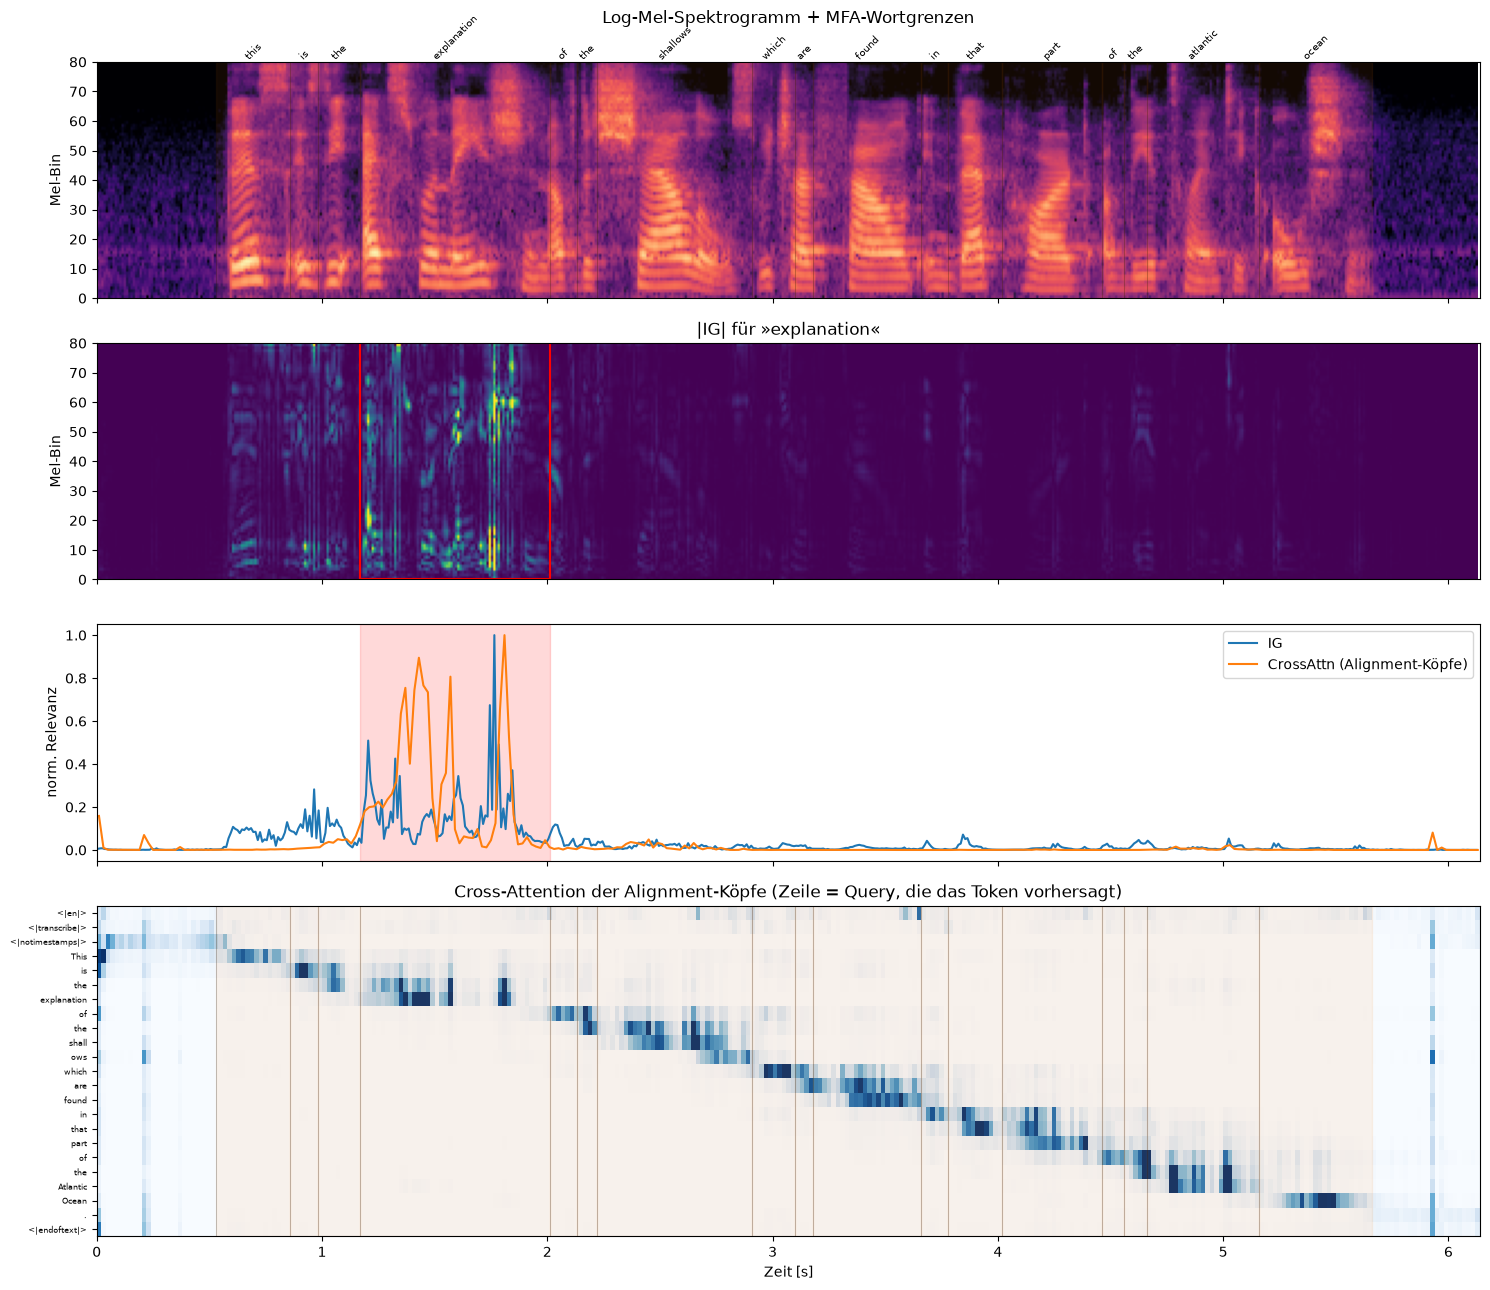

In [11]:
ex = RES[MAIN]["example"]; P = ex["prep"]; T, n_a = P["T"], P["n_a"]
wi = int(np.argmax([(w["end"] - w["start"]) * (not w["func"]) for w in P["words"]])); W = P["words"][wi]
print("Hypothese:", P["text"]); print("Fokuswort:", W["word"], f"[{W['start']:.2f}, {W['end']:.2f}] s")

def mark_words(ax, words, ymax=None, label=True):
    for w in words:
        ax.axvspan(w["start"], w["end"], color="tab:orange", alpha=0.08)
        ax.axvline(w["start"], color="k", lw=0.4, alpha=0.4)
        if label and ymax is not None:
            ax.text((w["start"] + w["end"]) / 2, ymax, w["word"], ha="center", va="bottom", fontsize=7, rotation=45)

fig, ax = plt.subplots(4, 1, figsize=(15, 13), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 1.4]))
ax[0].imshow(P["feats"][0, :, :T].cpu(), origin="lower", aspect="auto", extent=[0, T * HOP, 0, N_MEL], cmap="magma")
mark_words(ax[0], P["ref_words"], N_MEL); ax[0].set_ylabel("Mel-Bin"); ax[0].set_title("Log-Mel-Spektrogramm + MFA-Wortgrenzen", pad=28)
m = np.abs(ex["ig"][wi][:, :T]); ax[1].imshow(m, origin="lower", aspect="auto", extent=[0, T * HOP, 0, N_MEL], cmap="viridis", vmax=np.quantile(m, 0.999))
ax[1].axvspan(W["start"], W["end"], fill=False, ec="r", lw=1.5); ax[1].set_ylabel("Mel-Bin"); ax[1].set_title(f"|IG| für »{W['word']}«")
t = (np.arange(T) + 0.5) * HOP
ig_prof = np.abs(ex["ig"][wi]).sum(0)[:T]; ax[2].plot(t, ig_prof / ig_prof.max(), label="IG")
cr = ex["cross"]; rows = [p - 1 for p in W["tok_pos"]]; te = (np.arange(n_a) + 0.5) * ENC_HOP
heads = RES[MAIN]["align"] or [(l, h) for l in range(cr.shape[0]) for h in range(cr.shape[1])]
ca = np.mean([cr[l, h][rows].mean(0) for l, h in heads], 0); ax[2].plot(te, ca / ca.max(), label="CrossAttn (Alignment-Köpfe)")
ax[2].axvspan(W["start"], W["end"], color="r", alpha=0.15); ax[2].legend(); ax[2].set_ylabel("norm. Relevanz")
A = np.mean([cr[l, h] for l, h in heads], 0)
ax[3].imshow(A, aspect="auto", origin="upper", extent=[0, n_a * ENC_HOP, A.shape[0], 0], cmap="Blues", vmax=np.quantile(A, 0.995))
ax[3].set_yticks(np.arange(A.shape[0]) + 0.5); ax[3].set_yticklabels(ex["tokens"][:A.shape[0]], fontsize=6)
mark_words(ax[3], P["ref_words"], label=False); ax[3].set_xlabel("Zeit [s]"); ax[3].set_title("Cross-Attention der Alignment-Köpfe (Zeile = Query, die das Token vorhersagt)")
plt.tight_layout(); plt.savefig(f"{OUT}/example.png", dpi=130); plt.show()

## 7c Konvergenz von Integrated Gradients

Nach dem Axiom der *Completeness* muss $\sum_i \mathrm{IG}_i = f(x)-f(x_0)$ gelten. Der relative Fehler zeigt, ob die Riemann-Näherung des Integrals ausreicht; Zielwert ist < 5 %. Im ersten Lauf mit 32 Stützstellen lag der Median bei 32 % (tiny) bzw. 28 % (base). Deshalb wird hier für `n_conv` Äußerungen der Fehler für 16 bis 256 Stützstellen gemessen. Die Hauptanalyse nutzt `ig_steps` = 256.

**Begründung der Schrittzahl (Vorprüfung auf denselben ersten 3 Äußerungen, je 45 Wörter):** Der Median-Fehler fiel von 32 % / 39 % (32 Schritte, tiny / base) über 7 % / 9 % (64) und 1,2 % / 1,9 % (128) auf 0,2 % / 0,2 % (256). Unter 5 % lagen bei 128 Schritten erst 84 % / 67 % der Wörter, bei 256 Schritten 100 % / 98 %. Der Fehler sinkt pro Verdopplung etwa um den Faktor 4–5, wie es für die Mittelpunktsregel bei glattem Integranden zu erwarten ist. Die fehlende Konvergenz im ersten Lauf lag also allein an zu wenigen Stützstellen.

**Ergebnis des Hauptlaufs:** Mit 256 Stützstellen beträgt der Completeness-Fehler über alle Wörter im Median 0,2 % (tiny) bzw. 0,3 % (base). 98 % der Wörter liegen unter 5 %, das 90. Perzentil liegt bei 1,3 %. Die Konvergenztabelle unten reproduziert die Vorprüfung exakt. IG ist damit konvergiert, und alle IG-Ergebnisse in den Abschnitten 8, 9 und 12 gelten ohne den Vorbehalt des ersten Laufs.

Median                                     P90  \
model openai/whisper-base openai/whisper-tiny openai/whisper-base   
steps                                                               
16                  0.821               0.652               1.462   
32                  0.394               0.322               1.138   
64                  0.089               0.073               0.411   
128                 0.019               0.012               0.224   
256                 0.002               0.002               0.011   

                            Anteil_unter_5pct                      
model openai/whisper-tiny openai/whisper-base openai/whisper-tiny  
steps                                                              
16                  0.969               0.044               0.044  
32                  0.793               0.156               0.089  
64                  0.378               0.378               0.422  
128                 0.066               0.667               0.844  
256                 0.006               0.978               1.000

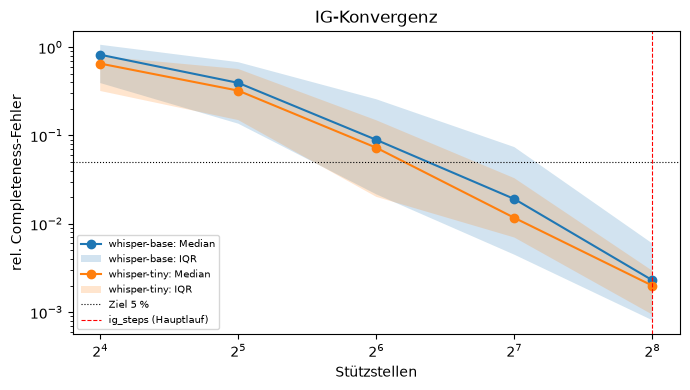

In [12]:
CV = pd.concat([RES[m]["ig_conv"] for m in MODELS])
conv = (CV.groupby(["model", "steps"]).rel_err
        .agg(Median="median", P90=lambda s: s.quantile(0.9), Anteil_unter_5pct=lambda s: (s < 0.05).mean())
        .round(3))
display(conv.unstack("model"))
fig, ax = plt.subplots(figsize=(7, 4))
for m, d in CV.groupby("model"):
    g = d.groupby("steps").rel_err
    ax.plot(g.median().index, g.median().values, marker="o", label=f"{m.split('/')[-1]}: Median")
    ax.fill_between(g.median().index, g.quantile(0.25).values, g.quantile(0.75).values, alpha=0.2, label=f"{m.split('/')[-1]}: IQR")
ax.axhline(0.05, color="k", ls=":", lw=0.8, label="Ziel 5 %"); ax.axvline(CFG["ig_steps"], color="r", ls="--", lw=0.8, label="ig_steps (Hauptlauf)")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("Stützstellen"); ax.set_ylabel("rel. Completeness-Fehler")
ax.set_title("IG-Konvergenz"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/ig_convergence.png", dpi=130); plt.show()

## 8 TF1 – Zeitliche Lokalisierung

**H1:** Gradientenbasierte Attribution konzentriert sich deutlich über Zufallsniveau auf das Wortsegment, mit Kontext von wenigen 100 ms.

Getestet wird einseitig per Wilcoxon-Vorzeichen-Rang-Test (`mass_in` > `chance`) auf **Äußerungsebene** (Mittel je Äußerung, n = 100), Holm-korrigiert über alle Modell-Methoden-Kombinationen. Vor- und Nachkontext werden ebenso gepaart verglichen. Für `mass_in` und Pointing werden 95-%-Cluster-Bootstrap-Intervalle angegeben. Ein Überhang in den *Nachkontext* wäre ein Hinweis auf Koartikulation bzw. darauf, dass der bidirektionale Encoder spätere Frames einbezieht.

Die Regression zur Wortdauer bei Funktionswörtern wurde nach dem ersten Lauf ergänzt und ist explorativ.

In [13]:
W_ALL = pd.concat([RES[m]["words"] for m in MODELS])
summary = (W_ALL.groupby(["model", "method"])
           .agg(n=("mass_in", "size"), mass_in=("mass_in", "mean"), chance=("chance", "mean"),
                lift_median=("lift", "median"), pointing=("hit", "mean"), pointing_chance=("hit_chance", "mean"),
                before=("before", "mean"), after=("after", "mean"),
                peak_off_ms=("peak_off", lambda s: 1000 * s.median()))
           .round(3))
display(summary)

# Tests auf Äußerungsebene + Cluster-Bootstrap-KI
U = W_ALL.groupby(["model", "method", "utt"])[["mass_in", "chance", "before", "after"]].mean().reset_index()
rows = []
for (m, meth), d in U.groupby(["model", "method"]):
    dw = W_ALL[(W_ALL.model == m) & (W_ALL.method == meth)]
    mi, pt = boot_ci(dw, "mass_in"), boot_ci(dw, "hit")
    rows.append(dict(model=m.split("/")[-1], method=meth, n_utt=len(d),
                     mass_in=dw.mass_in.mean(), mass_in_KI=f"[{mi[0]:.3f}, {mi[1]:.3f}]",
                     pointing=dw.hit.mean(), pointing_KI=f"[{pt[0]:.3f}, {pt[1]:.3f}]",
                     p_mass_in_gt_chance=stats.wilcoxon(d.mass_in - d.chance, alternative="greater").pvalue,
                     after_minus_before=(d.after - d.before).mean(),
                     p_after_vs_before=stats.wilcoxon(d.after - d.before).pvalue))
T1 = pd.DataFrame(rows)
T1["p_mass_in_holm"] = holm(T1.p_mass_in_gt_chance)
T1["p_after_before_holm"] = holm(T1.p_after_vs_before)
display(T1.drop(columns=["p_mass_in_gt_chance", "p_after_vs_before"]).set_index(["model", "method"])
        .style.format({"mass_in": "{:.3f}", "pointing": "{:.3f}", "after_minus_before": "{:+.3f}",
                       "p_mass_in_holm": "{:.1e}", "p_after_before_holm": "{:.1e}"}))

n  mass_in  chance  \
model               method                                               
openai/whisper-base CrossAttn (Alignment-Köpfe)  1779    0.563   0.043   
                    CrossAttn (alle Köpfe)       1779    0.187   0.043   
                    Grad×Δ                       1779    0.178   0.043   
                    IG                           1779    0.208   0.043   
                    Occlusion                    1779    0.566   0.043   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)  1756    0.473   0.043   
                    CrossAttn (alle Köpfe)       1756    0.249   0.043   
                    Grad×Δ                       1756    0.212   0.043   
                    IG                           1756    0.230   0.043   
                    Occlusion                    1756    0.642   0.043   

                                                 lift_median  pointing  \
model               method                                               
openai/whisper-base CrossAttn (Alignment-Köpfe)       16.929     0.853   
                    CrossAttn (alle Köpfe)             5.378     0.049   
                    Grad×Δ                             4.368     0.633   
                    IG                                 5.426     0.765   
                    Occlusion                         15.635     0.864   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)       12.455     0.679   
                    CrossAttn (alle Köpfe)             7.277     0.031   
                    Grad×Δ                             5.329     0.740   
                    IG                                 6.251     0.790   
                    Occlusion                         18.572     0.916   

                                                 pointing_chance  before  \
model               method                                                 
openai/whisper-base CrossAttn (Alignment-Köpfe)            0.049   0.134   
                    CrossAttn (alle Köpfe)                 0.049   0.123   
                    Grad×Δ                                 0.049   0.087   
                    IG                                     0.049   0.104   
                    Occlusion                              0.049   0.111   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)            0.049   0.050   
                    CrossAttn (alle Köpfe)                 0.049   0.147   
                    Grad×Δ                                 0.049   0.091   
                    IG                                     0.049   0.109   
                    Occlusion                              0.049   0.095   

                                                 after  peak_off_ms  
model               method                                           
openai/whisper-base CrossAttn (Alignment-Köpfe)  0.105        -20.0  
                    CrossAttn (alle Köpfe)       0.092       -905.0  
                    Grad×Δ                       0.090         -5.0  
                    IG                           0.096        -20.0  
                    Occlusion                    0.096        -25.0  
openai/whisper-tiny CrossAttn (Alignment-Köpfe)  0.272         60.0  
                    CrossAttn (alle Köpfe)       0.109      -1115.0  
                    Grad×Δ                       0.107          5.0  
                    IG                           0.101        -15.0  
                    Occlusion                    0.092        -20.0

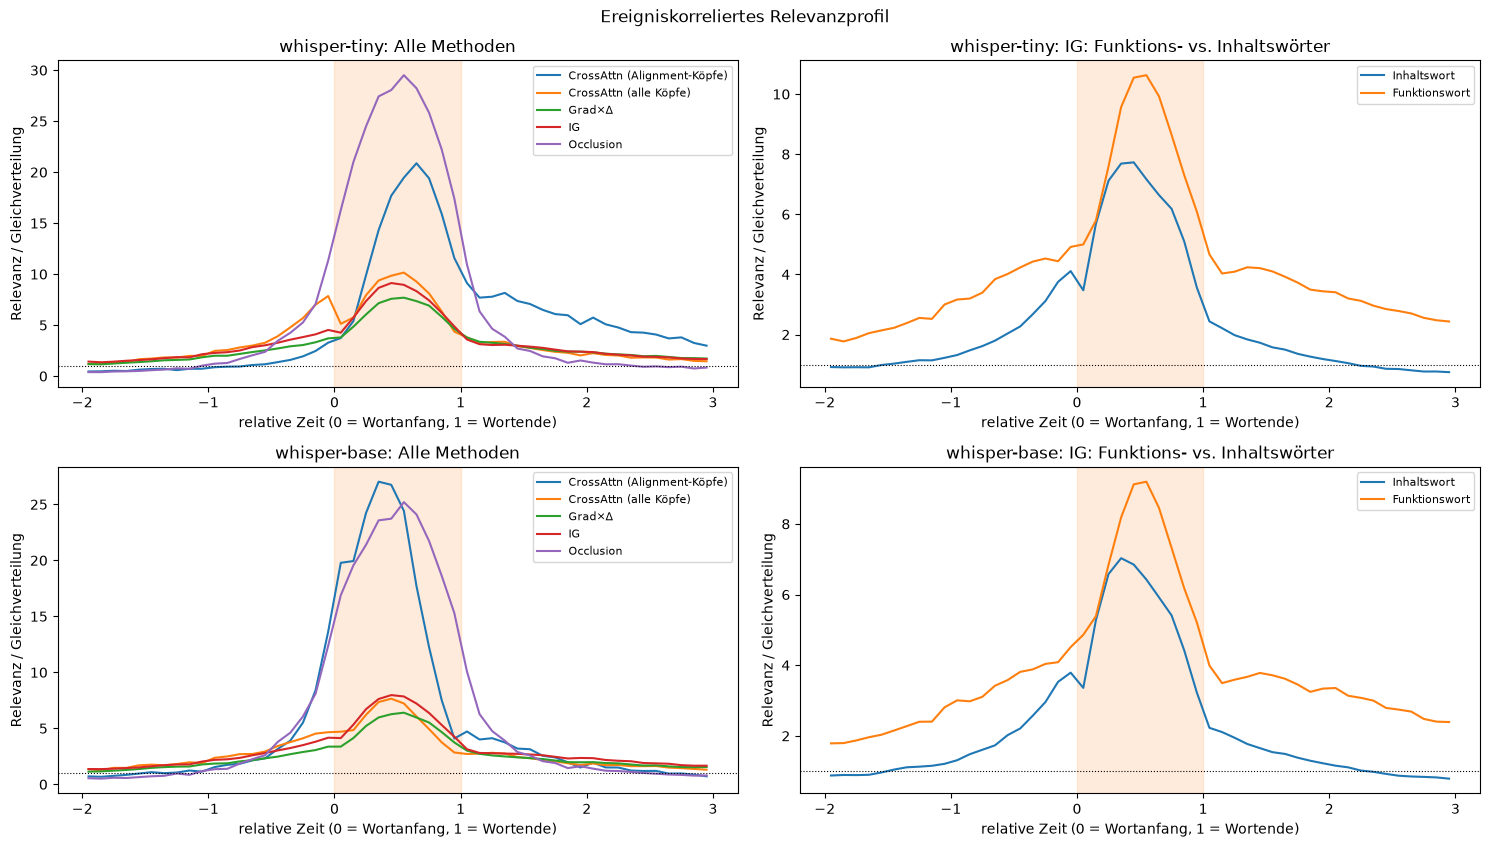

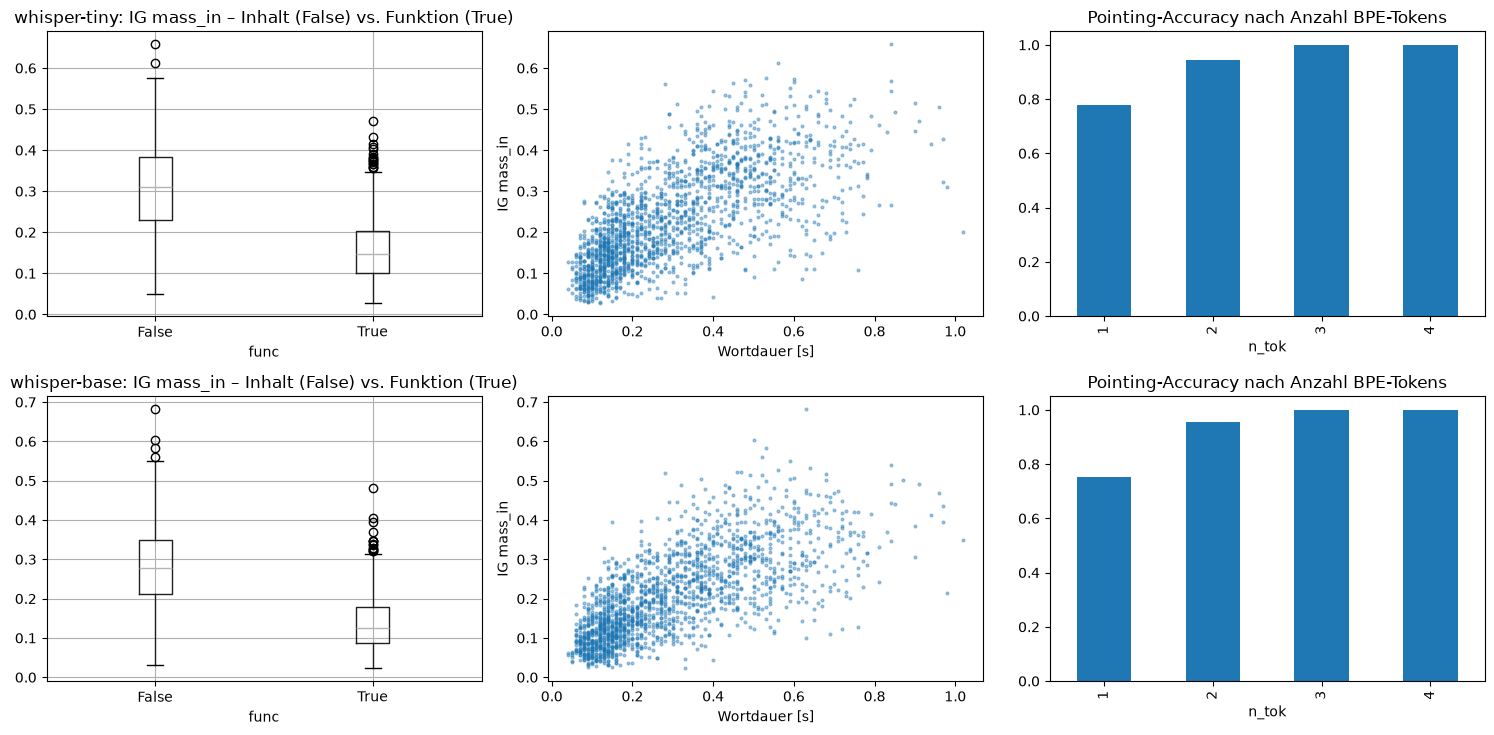

openai/whisper-tiny
  roh: lift Funktions- vs. Inhaltswort Median 7.17 vs 5.51 (Mann-Whitney p=7.3e-23); Spearman(Wortdauer, mass_in) = 0.72
  log_lift ~ Funktionswort + log(Dauer): β_Funktionswort = -0.168  95-%-KI [-0.239, -0.094]
  Pointing_über_Zufall ~ Funktionswort + log(Dauer): β_Funktionswort = -0.026  95-%-KI [-0.088, +0.038]


,lift Inhaltswort,lift Funktionswort,n Inhaltswort,n Funktionswort
Dauer-Quintil,,,,
1,NaN,8.36,NaN,352.0
2,9.15,7.22,31.0,321.0
3,6.57,5.84,155.0,199.0
4,5.82,4.85,318.0,33.0
5,4.76,3.26,340.0,7.0


openai/whisper-base
  roh: lift Funktions- vs. Inhaltswort Median 6.11 vs 4.84 (Mann-Whitney p=1.5e-16); Spearman(Wortdauer, mass_in) = 0.74
  log_lift ~ Funktionswort + log(Dauer): β_Funktionswort = -0.205  95-%-KI [-0.284, -0.120]
  Pointing_über_Zufall ~ Funktionswort + log(Dauer): β_Funktionswort = -0.043  95-%-KI [-0.108, +0.023]


,lift Inhaltswort,lift Funktionswort,n Inhaltswort,n Funktionswort
Dauer-Quintil,,,,
1,NaN,7.38,NaN,359.0
2,8.10,5.87,29.0,326.0
3,5.99,5.10,162.0,194.0
4,5.21,3.87,320.0,33.0
5,4.19,3.30,349.0,7.0


In [14]:
centers = (BINS[:-1] + BINS[1:]) / 2
fig, ax = plt.subplots(len(MODELS), 2, figsize=(15, 4.3 * len(MODELS)), squeeze=False)
for i, m in enumerate(MODELS):
    E = RES[m]["erp"]
    for meth, d in E.groupby("method"):
        ax[i, 0].plot(centers, np.nanmean(np.stack(d.prof), 0), label=meth)
    for f, d in E[E.method == "IG"].groupby("func"):
        ax[i, 1].plot(centers, np.nanmean(np.stack(d.prof), 0), label="Funktionswort" if f else "Inhaltswort")
    for a, ttl in zip(ax[i], ["Alle Methoden", "IG: Funktions- vs. Inhaltswörter"]):
        a.axvspan(0, 1, color="tab:orange", alpha=0.15); a.axhline(1, color="k", ls=":", lw=0.8)
        a.set_xlabel("relative Zeit (0 = Wortanfang, 1 = Wortende)"); a.set_ylabel("Relevanz / Gleichverteilung")
        a.set_title(f"{m.split('/')[-1]}: {ttl}"); a.legend(fontsize=8)
plt.suptitle("Ereigniskorreliertes Relevanzprofil"); plt.tight_layout(); plt.savefig(f"{OUT}/erp.png", dpi=130); plt.show()

fig, ax = plt.subplots(len(MODELS), 3, figsize=(15, 3.8 * len(MODELS)), squeeze=False)
for i, m in enumerate(MODELS):
    d = W_ALL[(W_ALL.model == m) & (W_ALL.method == "IG")]
    d.boxplot("mass_in", by="func", ax=ax[i, 0]); ax[i, 0].set_title(f"{m.split('/')[-1]}: IG mass_in – Inhalt (False) vs. Funktion (True)")
    ax[i, 1].scatter(d.w_dur, d.mass_in, s=4, alpha=0.4); ax[i, 1].set_xlabel("Wortdauer [s]"); ax[i, 1].set_ylabel("IG mass_in")
    d.groupby("n_tok").hit.mean().plot.bar(ax=ax[i, 2]); ax[i, 2].set_title("Pointing-Accuracy nach Anzahl BPE-Tokens")
plt.suptitle(""); plt.tight_layout(); plt.savefig(f"{OUT}/tf1_wordtypes.png", dpi=130); plt.show()

# Funktions- vs. Inhaltswörter: roh und mit Kontrolle der Wortdauer
for m in MODELS:
    d = W_ALL[(W_ALL.model == m) & (W_ALL.method == "IG")].copy()
    d["Funktionswort"] = d.func.astype(float); d["log_Dauer"] = np.log(d.w_dur)
    d["log_lift"] = np.log(d.lift.clip(lower=1e-6)); d["Pointing_über_Zufall"] = d.hit - d.hit_chance
    mw = stats.mannwhitneyu(d[d.func].lift, d[~d.func].lift)
    rho = stats.spearmanr(d.w_dur, d.mass_in)
    print(f"{m}\n  roh: lift Funktions- vs. Inhaltswort Median {d[d.func].lift.median():.2f} vs {d[~d.func].lift.median():.2f} "
          f"(Mann-Whitney p={mw.pvalue:.1e}); Spearman(Wortdauer, mass_in) = {rho.statistic:.2f}")
    for y in ("log_lift", "Pointing_über_Zufall"):
        b = ols_boot(d, y, ["Funktionswort", "log_Dauer"]).loc["Funktionswort"]
        print(f"  {y} ~ Funktionswort + log(Dauer): β_Funktionswort = {b.coef:+.3f}  95-%-KI [{b.ci_lo:+.3f}, {b.ci_hi:+.3f}]")
    d["Dauer-Quintil"] = pd.qcut(d.w_dur, 5, labels=False, duplicates="drop") + 1
    strat = d.groupby(["Dauer-Quintil", "func"]).agg(lift=("lift", "median"), n=("lift", "size")).unstack("func")
    strat.columns = [f"{a} {'Funktionswort' if f else 'Inhaltswort'}" for a, f in strat.columns]
    display(strat.round(2))

### Interpretation TF1 – Zeitliche Lokalisierung (H1)

* **H1 bestätigt:** Für alle Methoden und beide Modelle liegt `mass_in` weit über `chance` (≈ 0,043). Auf Äußerungsebene gilt `mass_in` > `chance` in jeder der 100 Äußerungen (Wilcoxon, Holm-korrigiert p < 1e-16). Der `lift` (Median) liegt zwischen 4,4 (Grad×Δ, base) und 18,6 (Occlusion, tiny). Das Pointing liegt für IG, Grad×Δ, Occlusion und die Alignment-Köpfe zwischen 0,63 und 0,92 (Zufall ≈ 0,05). Die Ausnahme ist der Mittelwert über alle Cross-Attention-Köpfe mit 0,03 / 0,05 (Abschnitt 10). Die Cluster-Bootstrap-Intervalle sind eng, z. B. IG-Pointing 0,79 [0,77; 0,81] (tiny) und 0,77 [0,74; 0,79] (base).
* **Occlusion lokalisiert am schärfsten** (`mass_in` 0,64 / 0,57, Pointing 0,92 / 0,86 für tiny / base). IG ist diffuser (`mass_in` 0,23 / 0,21), trifft mit dem **Peak** aber in 79 % / 77 % der Fälle das Wort. Das ist kein Widerspruch: Der Gradient verteilt kleine Beträge über alle 3000 Frames, das Maximum liegt aber im Wort. Weil IG jetzt konvergiert ist (Abschnitt 7c), ist diese Diffusität eine Eigenschaft der Methode und kein Näherungsfehler.
* **Kontext:** Bei IG, Grad×Δ und Occlusion ist die Masse in den 300 ms vor und nach dem Wort etwa gleich groß (je ca. 0,09–0,11). Die Differenz „nach − vor“ liegt zwischen −0,016 und +0,015. Einzelne dieser Differenzen sind signifikant (nach globaler Korrektur IG in beiden Modellen und Grad×Δ bei tiny), inhaltlich aber vernachlässigbar. Es gibt also einen symmetrischen Kontext von wenigen 100 ms und **keinen Überhang in den Nachkontext**; das passt zu Koartikulation in beide Richtungen. Die einzige deutliche Ausnahme ist die Cross-Attention der Alignment-Köpfe von `whisper-tiny`: 0,22 mehr Masse nach als vor dem Wort (0,27 gegen 0,05, Peak-Offset +60 ms). Bei `whisper-base` fehlt dieser Versatz (−20 ms). Das ist eine Eigenschaft dieser Köpfe. Würde man Zeitstempel direkt aus ihnen ablesen, wären sie bei tiny nach hinten verschoben. Whispers eigenes Verfahren (Medianfilter und DTW über diese Köpfe) wurde hier nicht nachgebildet; ob es den Versatz ausgleicht, ist offen.
* **Funktions- vs. Inhaltswörter:** Roh haben Funktionswörter den **höheren** `lift` (Median 7,17 gegen 5,51 bei tiny, 6,11 gegen 4,84 bei base). Das liegt am Zufallsniveau: Funktionswörter sind kurz, und `mass_in` hängt stark von der Wortdauer ab (Spearman 0,72 / 0,74). Wird die Wortdauer in einer Regression kontrolliert (explorativ, nach dem ersten Lauf ergänzt), **kehrt sich der Effekt um**: Bei gleicher Dauer ist der `lift` von Funktionswörtern um ca. 15–19 % niedriger (β für log `lift` −0,17 [−0,24; −0,09] bzw. −0,21 [−0,28; −0,12]). Auch innerhalb jedes Dauer-Quintils, in dem beide Wortarten vorkommen, liegt ihr Median-`lift` unter dem der Inhaltswörter. Beim Pointing über Zufall gibt es keinen Unterschied (die Intervalle enthalten 0). Funktionswörter werden also am richtigen Ort, aber etwas diffuser lokalisiert. Eine mögliche, hier nicht geprüfte Erklärung: Funktionswörter werden stärker aus dem Decoder-Kontext vorhergesagt und brauchen weniger akustische Evidenz.

## 9 TF2 – Spektrale Merkmale

Für jedes Wort wird die |IG|-Masse im Wortsegment pro Mel-Bin normiert und mit dem Energieprofil $x-x_0$ im selben Segment verglichen. Ein Verhältnis > 1 heißt: Das Band ist *relevanter, als seine Energie erwarten lässt*.

**Achtung, Zirkularität:** IG $=(x-x_0)\odot\bar g$ enthält die Energie als Faktor. Eine Korrelation zwischen |IG| und Energie ist deshalb zum Teil ein Artefakt der Definition. Als energiefreie Vergleichsgröße dient der mittlere Gradient $|\bar g|$: Korreliert auch er mit der Energie, reagiert das Modell tatsächlich vor allem auf energiereiche Bänder.

Die Band-Occlusion liefert eine kausale Gegenprobe. Weil tiefe Bänder die meiste Energie tragen, ist ihr Entfernen der größte Eingriff. Deshalb wird der Abfall von $\log p$ zusätzlich **pro entfernter Energieeinheit** angegeben (Verhältnis der Mittelwerte über alle Wörter).

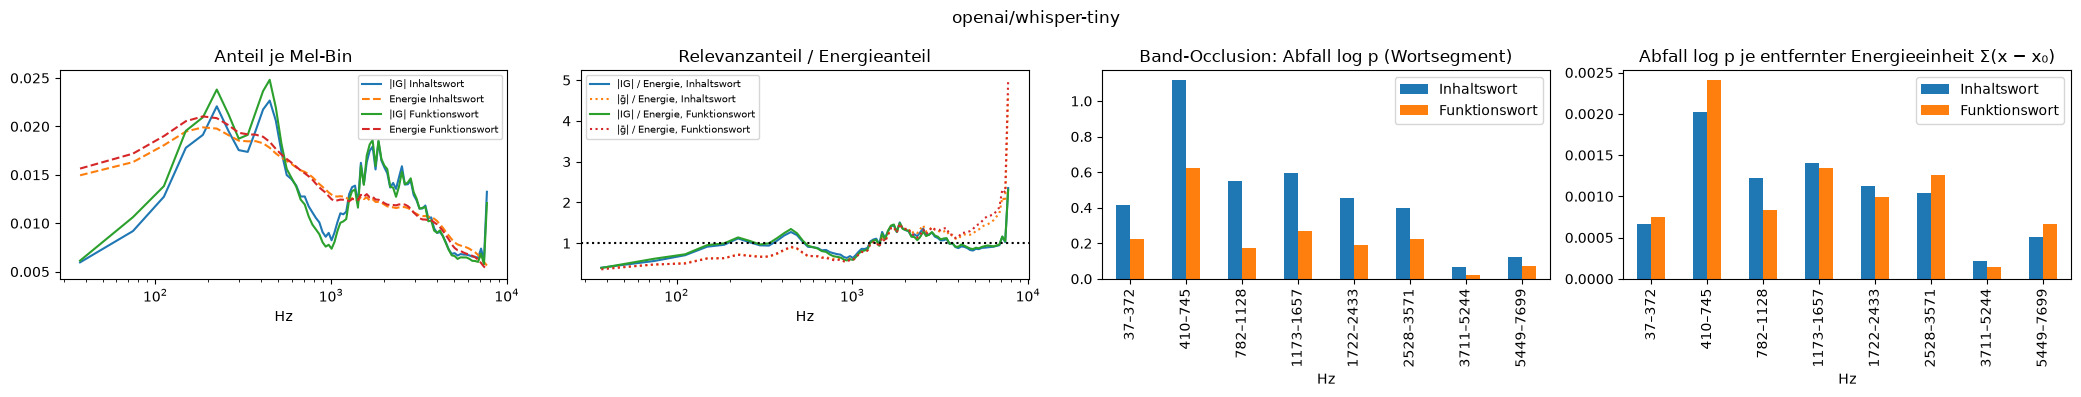

openai/whisper-tiny: Median Spearman je Wort – |IG| vs. Energie 0.67, |ḡ| vs. Energie 0.15
  wichtigstes Band roh: 410–745 Hz | je Energieeinheit: 410–745 Hz


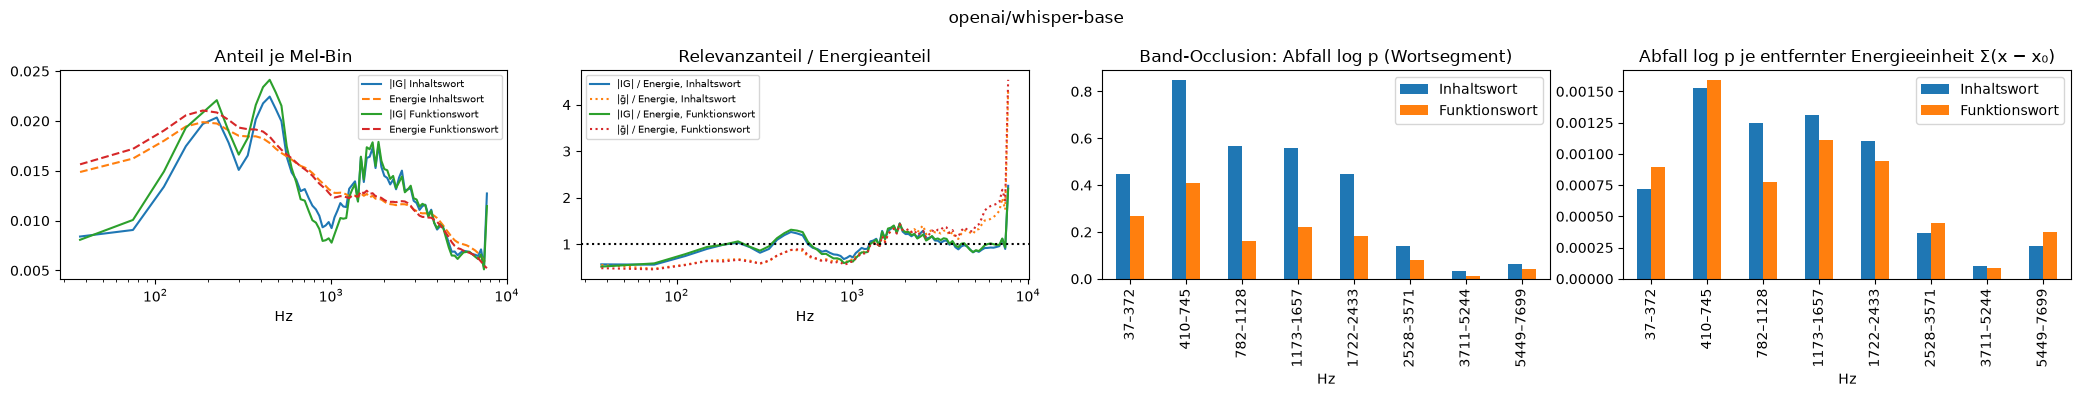

openai/whisper-base: Median Spearman je Wort – |IG| vs. Energie 0.67, |ḡ| vs. Energie 0.13
  wichtigstes Band roh: 410–745 Hz | je Energieeinheit: 410–745 Hz


In [15]:
freqs = librosa.mel_frequencies(n_mels=N_MEL + 2, fmin=0, fmax=SR / 2)[1:-1]   # Mittenfrequenzen der Slaney-Mel-Filter
fn = lambda f: "Funktionswort" if f else "Inhaltswort"
for m in MODELS:
    S, B, e = RES[m]["spec"], RES[m]["bands"], RES[m]["band_edges"]
    nb = len(e) - 1; bcols, ecols = [f"b{k}" for k in range(nb)], [f"e{k}" for k in range(nb)]
    bl = [f"{freqs[e[k]]:.0f}–{freqs[e[k + 1] - 1]:.0f}" for k in range(nb)]
    fig, ax = plt.subplots(1, 4, figsize=(21, 4))
    for f, d in S.groupby("func"):
        ig_m, g_m, en_m = np.stack(d.ig).mean(0), np.stack(d.grad).mean(0), np.stack(d.energy).mean(0)
        ax[0].plot(freqs, ig_m, label=f"|IG| {fn(f)}"); ax[0].plot(freqs, en_m, "--", label=f"Energie {fn(f)}")
        ax[1].plot(freqs, ig_m / en_m, label=f"|IG| / Energie, {fn(f)}"); ax[1].plot(freqs, g_m / en_m, ":", label=f"|ḡ| / Energie, {fn(f)}")
    ax[0].set_title("Anteil je Mel-Bin"); ax[1].set_title("Relevanzanteil / Energieanteil"); ax[1].axhline(1, color="k", ls=":")
    for a in ax[:2]: a.set_xscale("log"); a.set_xlabel("Hz"); a.legend(fontsize=7)
    g = B.groupby("func")
    drop = g[bcols].mean().T; drop.index = bl; drop.columns = [fn(c) for c in drop.columns]
    eff = pd.DataFrame(g[bcols].mean().to_numpy().T / g[ecols].mean().to_numpy().T, index=bl, columns=drop.columns)
    drop.plot.bar(ax=ax[2]); ax[2].set_title("Band-Occlusion: Abfall log p (Wortsegment)"); ax[2].set_xlabel("Hz")
    eff.plot.bar(ax=ax[3]); ax[3].set_title("Abfall log p je entfernter Energieeinheit Σ(x − x₀)"); ax[3].set_xlabel("Hz")
    plt.suptitle(m); plt.tight_layout(); plt.savefig(f"{OUT}/tf2_spectral_{m.split('/')[-1]}.png", dpi=130); plt.show()

    rho_ig = np.nanmedian([stats.spearmanr(a, b).statistic for a, b in zip(S.ig, S.energy)])
    rho_g = np.nanmedian([stats.spearmanr(a, b).statistic for a, b in zip(S.grad, S.energy)])
    all_drop = B[bcols].mean().to_numpy(); all_eff = all_drop / B[ecols].mean().to_numpy()
    print(f"{m}: Median Spearman je Wort – |IG| vs. Energie {rho_ig:.2f}, |ḡ| vs. Energie {rho_g:.2f}\n"
          f"  wichtigstes Band roh: {bl[all_drop.argmax()]} Hz | je Energieeinheit: {bl[all_eff.argmax()]} Hz")

### Interpretation TF2 – Spektrale Merkmale

* **Wichtigstes Band:** Die Band-Occlusion nennt für beide Modelle **410–745 Hz** als wichtigstes Band, sowohl beim rohen Abfall von log p als auch pro entfernter Energieeinheit. Der Befund ist also nicht nur eine Folge davon, dass dieses Band viel Energie trägt. In diesem Band liegen der erste Formant vieler Vokale, aber auch Harmonische der Grundfrequenz; die Einteilung in acht grobe Bandgruppen kann das nicht trennen. Pro Energieeinheit folgen 1173–1657 Hz und 782–1128 Hz (Bereich, in dem bei vielen Vokalen der zweite Formant liegt). Oberhalb von ca. 3,7 kHz ist der Effekt in beiden Maßen klein.
* **Die Korrelation von |IG| mit der Energie ist größtenteils ein Artefakt.** |IG| und Energieprofil korrelieren im Median mit 0,67. Der mittlere Gradient |ḡ|, der den Energiefaktor $(x-x_0)$ nicht enthält, korreliert nur mit 0,15 (tiny) bzw. 0,13 (base). Die Ähnlichkeit von IG und Energie entsteht also vor allem durch die Multiplikation mit $(x-x_0)$ in der IG-Definition. Relativ zu seinem Energieanteil ist der Gradient unter 1 kHz unterdurchschnittlich (Verhältnis ca. 0,6–0,7) und darüber überdurchschnittlich (1–4 kHz ca. 1,15, über 4 kHz ca. 1,7). Pro Einheit reagiert das Modell also eher auf höhere Frequenzen. Dort ist aber wenig Energie vorhanden, deshalb bleibt der kausale Effekt der Band-Occlusion oberhalb von 3,7 kHz klein.
* **Inhalts- vs. Funktionswörter:** Roh reagieren Inhaltswörter in allen acht Bändern stärker auf Band-Occlusion als Funktionswörter. Pro Energieeinheit ist der Unterschied klein und uneinheitlich; in vier der acht Bänder liegen Funktionswörter sogar höher. Der rohe Unterschied geht also zu einem großen Teil darauf zurück, dass bei den kürzeren Funktionswörtern weniger Energie entfernt wird.
* Die Befunde sind zwischen tiny und base sehr ähnlich (Abbildungen für beide Modelle oben).

## 10 TF3 – Cross-Attention-Köpfe des Decoders

**H2:** Nur wenige Köpfe in mittleren und späten Decoder-Schichten richten ihre Cross-Attention eng an den Wortgrenzen aus. Diese sollten mit OpenAIs `alignment_heads` übereinstimmen.

Die Heatmap zeigt die Pointing-Accuracy pro (Schicht, Kopf). Die Alignment-Köpfe sind mit ★ markiert. Rechts steht der Anteil der Attention auf dem Padding.

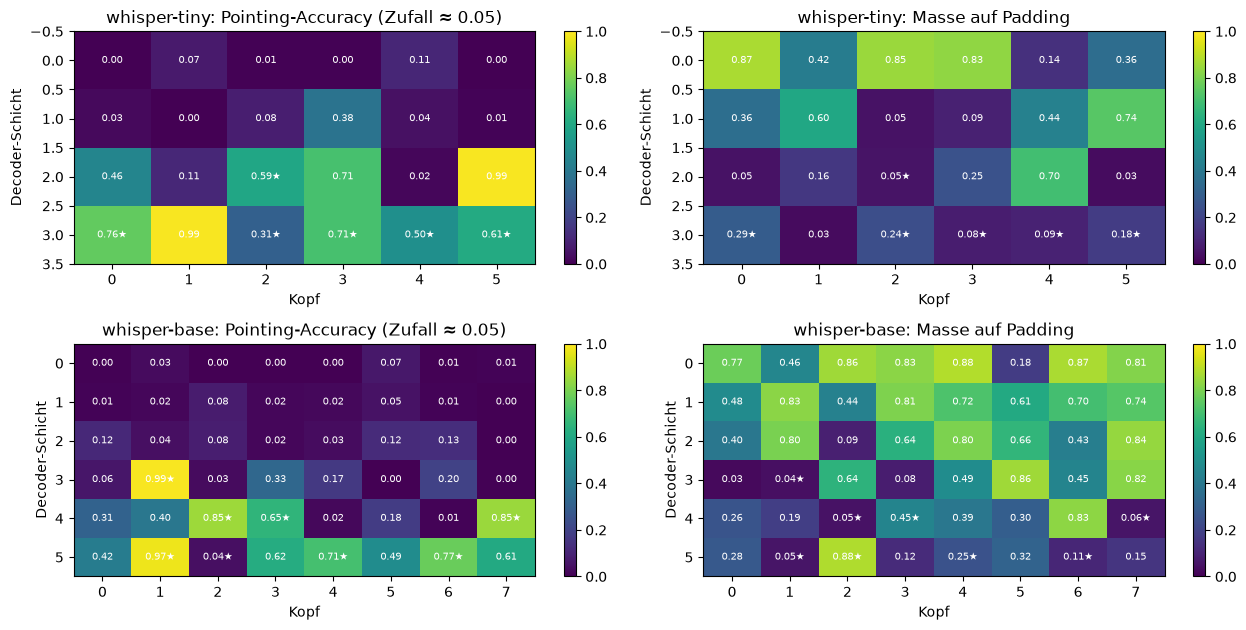

openai/whisper-tiny: Top-6 Köpfe [(3, 1), (2, 5), (3, 0), (3, 3), (2, 3), (3, 5)] | Überlappung mit alignment heads: 3/6 | Köpfe mit Pointing > 0.5: 7/24 | Mittel je Schicht: [0.03 0.09 0.48 0.65]
   Pointing der alignment heads: {'C2.2': 0.59, 'C3.0': 0.76, 'C3.2': 0.31, 'C3.3': 0.71, 'C3.4': 0.5, 'C3.5': 0.61}
openai/whisper-base: Top-8 Köpfe [(3, 1), (5, 1), (4, 2), (4, 7), (5, 6), (5, 4), (4, 3), (5, 3)] | Überlappung mit alignment heads: 7/8 | Köpfe mit Pointing > 0.5: 9/48 | Mittel je Schicht: [0.02 0.03 0.07 0.22 0.41 0.58]
   Pointing der alignment heads: {'C3.1': 0.99, 'C4.2': 0.85, 'C4.3': 0.65, 'C4.7': 0.85, 'C5.1': 0.97, 'C5.2': 0.04, 'C5.4': 0.71, 'C5.6': 0.77}


In [16]:
fig, axes = plt.subplots(len(MODELS), 2, figsize=(13, 3.2 * len(MODELS)), squeeze=False)
for i, m in enumerate(MODELS):
    r = RES[m]; chance = W_ALL[(W_ALL.model == m) & (W_ALL.method == "IG")].hit_chance.mean()
    for j, (k, ttl) in enumerate([("hit", f"Pointing-Accuracy (Zufall ≈ {chance:.2f})"), ("pad", "Masse auf Padding")]):
        a = axes[i, j]; M = r["cross"][k]
        im = a.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto"); plt.colorbar(im, ax=a)
        for (l, h), v in np.ndenumerate(M):
            a.text(h, l, f"{v:.2f}" + ("★" if r["align"] and (l, h) in r["align"] else ""), ha="center", va="center", fontsize=7, color="w")
        a.set_xlabel("Kopf"); a.set_ylabel("Decoder-Schicht"); a.set_title(f"{m.split('/')[-1]}: {ttl}")
plt.tight_layout(); plt.savefig(f"{OUT}/tf3_cross_heads.png", dpi=130); plt.show()

for m in MODELS:
    r = RES[m]; M = r["cross"]["hit"]; al = r["align"] or []; k = len(al) or 6
    top = [(int(l), int(h)) for l, h in zip(*np.unravel_index(np.argsort(-M, axis=None), M.shape))]
    print(f"{m}: Top-{k} Köpfe {top[:k]} | Überlappung mit alignment heads: {len(set(top[:k]) & set(al))}/{len(al)} | "
          f"Köpfe mit Pointing > 0.5: {(M > 0.5).sum()}/{M.size} | Mittel je Schicht: {M.mean(1).round(2)}")
    print("   Pointing der alignment heads:", {f"C{l}.{h}": round(float(M[l, h]), 2) for l, h in al})

### Interpretation TF3 – Cross-Attention-Köpfe (H2)

* **H2 teilweise bestätigt.** *Wenige Köpfe in späten Schichten* stimmt: Nur 7 von 24 (tiny) bzw. 9 von 48 (base) Köpfen haben ein Pointing > 0,5, fast alle in den späten Schichten (Mittel je Schicht tiny 0,03 → 0,65, base 0,02 → 0,58). Der beste Kopf (in beiden Modellen Schicht 3 / Kopf 1) erreicht 0,99.
* **Aber: Diese Köpfe sind nur teilweise die `alignment_heads`.** Im Mittel sind die Alignment-Köpfe deutlich besser als der Durchschnitt (Pointing 0,58 / 0,73 gegen 0,31 / 0,22). Unter den Top-6 bzw. Top-8 Köpfen sind aber nur 3 von 6 (tiny) bzw. 7 von 8 (base) Alignment-Köpfe. In `whisper-tiny` liegt der beste Kopf (Schicht 3 / Kopf 1) außerhalb der Alignment-Köpfe, und der schwächste Alignment-Kopf (Schicht 3 / Kopf 2) erreicht nur 0,31. In `whisper-base` ist ein Alignment-Kopf (Schicht 5 / Kopf 2) ein Padding-Sink (Pointing 0,04, Padding-Masse 0,88). OpenAIs Auswahl ist offenbar für Zeitstempel per DTW optimiert und nicht identisch mit „am besten lokalisierender Kopf“.
* **Mittelung über alle Köpfe ist unbrauchbar:** Pointing 0,03 / 0,05 (≈ Zufall 0,05), weil sich Sink-Köpfe und frühe Schichten mit den lokalisierenden Köpfen mischen. Es bleibt aber etwas Masse im Wort (`lift` 7,3 / 5,4).
* **Attention Sinks:** In der ersten Decoder-Schicht liegt im Mittel mehr als die Hälfte der Masse auf dem 30-s-Padding (0,58 / 0,71), einzelne Köpfe erreichen 0,87 / 0,88. Hohe Padding-Masse ist kein Lokalisierungsergebnis.

## 11 TF4 – Self-Attention-Köpfe des Encoders

**H3:** In frühen Encoder-Schichten dominieren lokale, diagonale Muster, in späteren Schichten globalere Muster.

**Tests.** (1) Spearman zwischen Schichtindex und Kopf-Kennzahl über alle Köpfe, einseitig in Richtung der Hypothese. Mit nur 4 bzw. 6 Schichten hat dieser Test wenig Teststärke. (2) Nach dem ersten Lauf ergänzt und deshalb **explorativ**: ein Test auf **Äußerungsebene**. Für jede Äußerung wird die Steigung des Schichtmittels von `local` bzw. `mean_dist` über die Schichten bestimmt und per Wilcoxon gegen 0 getestet (einseitig, n = 100). Dieser Test verallgemeinert über Eingaben, nicht über Modelle.

Heuristische Typisierung pro Kopf. Die Schwellen für `local` sind auf das Zufallsniveau bezogen: Bei einer mittleren Äußerung von ca. 340 Encoder-Frames liegen bei Gleichverteilung nur ca. 1,5 % der Masse im Fenster ±2 Frames.
* *Sink*: `pad_mass` > 0.5
* *Vorgänger/Nachfolger*: `prev` oder `next` > 0.3
* *lokal*: `local` ≥ 0.25 (mehr als das 15-Fache des Zufallsniveaus)
* *teils lokal*: `local` ≥ 0.10
* sonst *global*

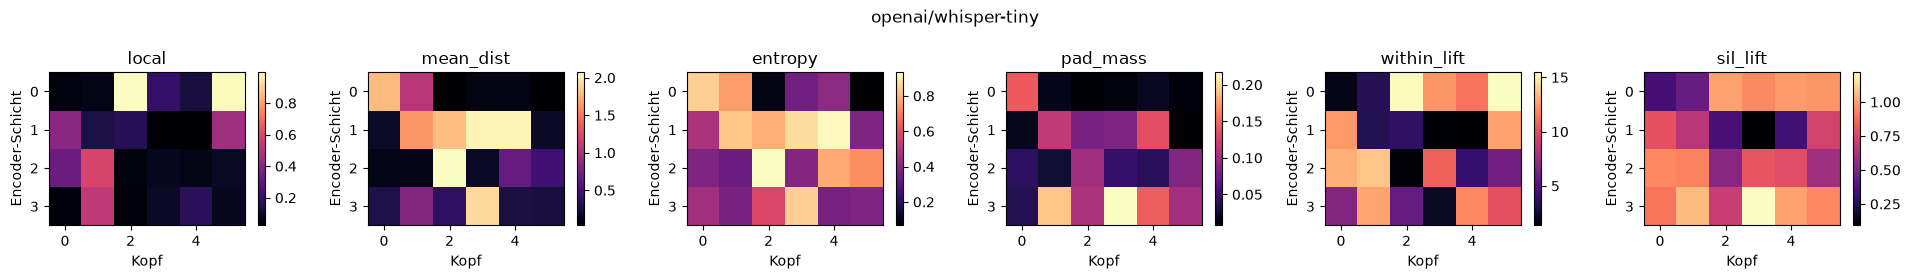

,0,1,2,3,4,5
Schicht,,,,,,
0,global,global,Nachfolger,teils lokal,teils lokal,Vorgänger
1,lokal,teils lokal,teils lokal,global,global,lokal
2,lokal,lokal,global,global,global,global
3,global,lokal,global,global,teils lokal,global


openai/whisper-tiny
  Köpfe:      Spearman(Schicht, mean_dist) = +0.22 (p einseitig = 0.15), Spearman(Schicht, local) = -0.20 (p einseitig = 0.17)
  Äußerungen: Steigung local je Schicht Median -0.0744 (Anteil < 0: 1.00, p = 1.9e-18); Steigung mean_dist Median -0.0263 s (Anteil > 0: 0.18, p = 1)


,local (Mittel),local (SD über Köpfe),mean_dist [s],Typen
Schicht,,,,
0,0.408,0.416,0.522,"global×2, teils lokal×2, Nachfolger×1, Vorgäng..."
1,0.206,0.169,1.308,"lokal×2, teils lokal×2, global×2"
2,0.201,0.198,0.602,"global×4, lokal×2"
3,0.162,0.169,0.657,"global×4, lokal×1, teils lokal×1"


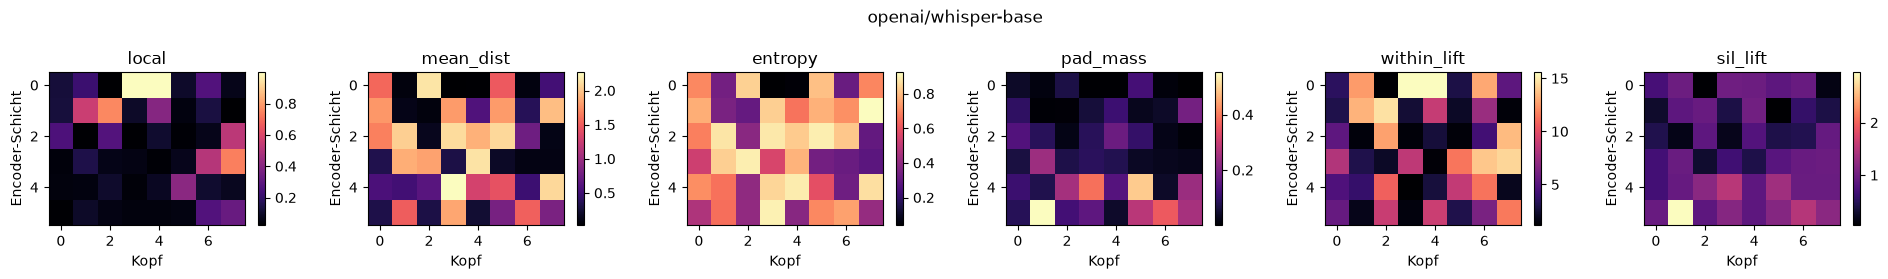

,0,1,2,3,4,5,6,7
Schicht,,,,,,,,
0,teils lokal,teils lokal,global,Nachfolger,Vorgänger,teils lokal,lokal,global
1,teils lokal,lokal,Nachfolger,global,lokal,global,teils lokal,global
2,lokal,global,lokal,global,teils lokal,global,global,lokal
3,global,teils lokal,global,global,global,global,lokal,lokal
4,global,global,teils lokal,global,global,lokal,teils lokal,global
5,global,Sink,global,global,global,global,lokal,lokal


openai/whisper-base
  Köpfe:      Spearman(Schicht, mean_dist) = +0.12 (p einseitig = 0.21), Spearman(Schicht, local) = -0.26 (p einseitig = 0.038)
  Äußerungen: Steigung local je Schicht Median -0.0455 (Anteil < 0: 1.00, p = 1.9e-18); Steigung mean_dist Median +0.0191 s (Anteil > 0: 0.91, p = 9.4e-16)


,local (Mittel),local (SD über Köpfe),mean_dist [s],Typen
Schicht,,,,
0,0.350,0.381,0.741,"teils lokal×3, global×2, Nachfolger×1, Vorgäng..."
1,0.269,0.254,1.064,"global×3, teils lokal×2, lokal×2, Nachfolger×1"
2,0.165,0.165,1.353,"global×4, lokal×3, teils lokal×1"
3,0.208,0.248,0.862,"global×5, lokal×2, teils lokal×1"
4,0.116,0.114,1.161,"global×5, teils lokal×2, lokal×1"
5,0.115,0.108,0.920,"global×5, lokal×2, Sink×1"


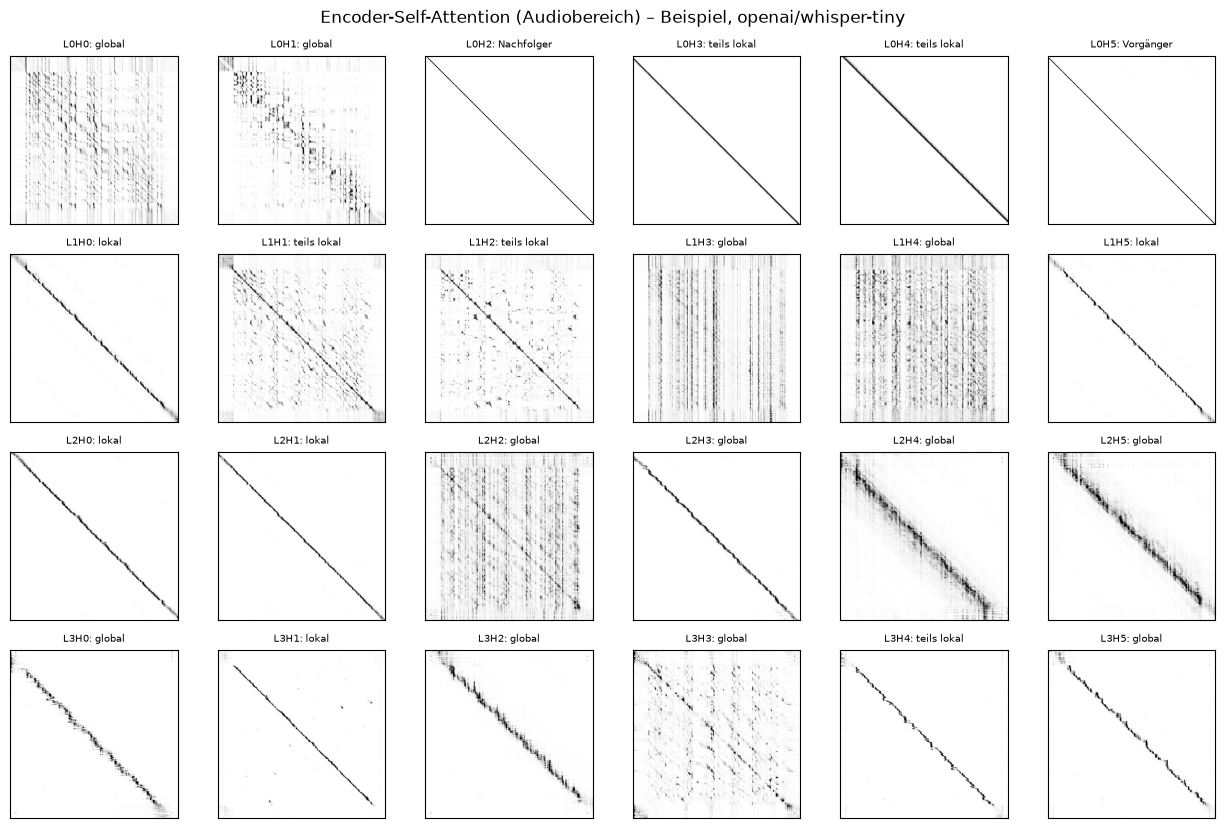

In [17]:
def head_type(s, l, h):
    if s["pad_mass"][l, h] > 0.5: return "Sink"
    if s["prev"][l, h] > 0.3: return "Vorgänger"
    if s["next"][l, h] > 0.3: return "Nachfolger"
    if s["local"][l, h] >= 0.25: return "lokal"
    if s["local"][l, h] >= 0.10: return "teils lokal"
    return "global"

keys = ["local", "mean_dist", "entropy", "pad_mass", "within_lift", "sil_lift"]
H3_TESTS = []   # für die globale Mehrfachtest-Korrektur (Abschnitt 13b)
for m in MODELS:
    s, EU = RES[m]["enc"], RES[m]["enc_utt"]
    fig, ax = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 2.8))
    for a, k in zip(ax, keys):
        im = a.imshow(s[k], aspect="auto", cmap="magma"); plt.colorbar(im, ax=a); a.set_title(k)
        a.set_xlabel("Kopf"); a.set_ylabel("Encoder-Schicht")
    plt.suptitle(m); plt.tight_layout(); plt.savefig(f"{OUT}/tf4_enc_{m.split('/')[-1]}.png", dpi=130); plt.show()
    types = pd.DataFrame([[head_type(s, l, h) for h in range(s["local"].shape[1])] for l in range(s["local"].shape[0])])
    types.index.name = "Schicht"; display(types)

    L = np.repeat(np.arange(s["local"].shape[0]), s["local"].shape[1])
    r1 = stats.spearmanr(L, s["mean_dist"].ravel(), alternative="greater")
    r2 = stats.spearmanr(L, s["local"].ravel(), alternative="less")
    lay = np.arange(EU["local"].shape[1])
    sl_loc = np.array([np.polyfit(lay, u.mean(-1), 1)[0] for u in EU["local"]])
    sl_dist = np.array([np.polyfit(lay, u.mean(-1), 1)[0] for u in EU["mean_dist"]])
    p_loc = stats.wilcoxon(sl_loc, alternative="less").pvalue
    p_dist = stats.wilcoxon(sl_dist, alternative="greater").pvalue
    sm = m.split("/")[-1]
    H3_TESTS += [dict(Hypothese="H3", Test=f"Köpfe: Spearman(Schicht, mean_dist) positiv · {sm}", Art="geplant", p=r1.pvalue),
                 dict(Hypothese="H3", Test=f"Köpfe: Spearman(Schicht, local) negativ · {sm}", Art="geplant", p=r2.pvalue),
                 dict(Hypothese="H3", Test=f"Äußerungen: Steigung local negativ · {sm}", Art="nach erstem Lauf ergänzt", p=p_loc),
                 dict(Hypothese="H3", Test=f"Äußerungen: Steigung mean_dist positiv · {sm}", Art="nach erstem Lauf ergänzt", p=p_dist)]
    print(f"{m}\n  Köpfe:      Spearman(Schicht, mean_dist) = {r1.statistic:+.2f} (p einseitig = {r1.pvalue:.2g}), "
          f"Spearman(Schicht, local) = {r2.statistic:+.2f} (p einseitig = {r2.pvalue:.2g})")
    print(f"  Äußerungen: Steigung local je Schicht Median {np.median(sl_loc):+.4f} (Anteil < 0: {(sl_loc < 0).mean():.2f}, p = {p_loc:.2g}); "
          f"Steigung mean_dist Median {np.median(sl_dist):+.4f} s (Anteil > 0: {(sl_dist > 0).mean():.2f}, p = {p_dist:.2g})")
    display(pd.DataFrame({"local (Mittel)": EU["local"].mean(-1).mean(0), "local (SD über Köpfe)": s["local"].std(1),
                          "mean_dist [s]": EU["mean_dist"].mean(-1).mean(0),
                          "Typen": [", ".join(f"{t}×{n}" for t, n in types.loc[l].value_counts().items()) for l in types.index]},
                         index=pd.Index(lay, name="Schicht")).round(3))

ex = RES[MAIN]["example"]; Le, He = ex["enc"].shape[:2]
fig, ax = plt.subplots(Le, He, figsize=(2.1 * He, 2.1 * Le))
for l in range(Le):
    for h in range(He):
        a = ax[l, h]; M = ex["enc"][l, h].astype(np.float32)
        a.imshow(M, cmap="Greys", vmax=np.quantile(M, 0.995)); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"L{l}H{h}: {head_type(RES[MAIN]['enc'], l, h)}", fontsize=7)
plt.suptitle(f"Encoder-Self-Attention (Audiobereich) – Beispiel, {MAIN}"); plt.tight_layout()
plt.savefig(f"{OUT}/tf4_enc_maps.png", dpi=110); plt.show()

### Interpretation TF4 – Encoder-Self-Attention (H3)

* **H3 teilweise bestätigt, aber nur explorativ.** Der geplante Test über die **Köpfe** zeigt keinen belastbaren Trend: Die Spearman-Korrelation zwischen Schicht und `local` beträgt ρ = −0,20 (p = 0,17, tiny) bzw. −0,26 (p = 0,038, base; nach globaler Korrektur p = 0,31), für `mean_dist` ρ = +0,22 / +0,12 (p = 0,15 / 0,21, jeweils einseitig). Mit 4 bzw. 6 Schichten hat dieser Test wenig Teststärke. Der nach dem ersten Lauf ergänzte Test über die **Äußerungen** ist eindeutig: In allen 100 Äußerungen nimmt die mittlere Lokalität mit der Schichttiefe ab (Steigung −0,074 bzw. −0,046 pro Schicht, p < 1e-16 auch nach globaler Korrektur). Die Aufmerksamkeitsdistanz wächst dagegen nur bei base (in 91 % der Äußerungen). Bei tiny sinkt sie sogar leicht, weil Schicht 1 die größte Distanz hat (1,31 s gegen 0,66 s in der letzten Schicht).
* **Einordnung des p-Werts:** Das Modell hat feste Gewichte. Der Test auf Äußerungsebene misst deshalb, wie konsistent dasselbe Modellmerkmal bei verschiedenen Eingaben auftritt. Der sehr kleine p-Wert heißt „tritt bei jeder Eingabe auf“, nicht „großer Effekt“, und er verallgemeinert nicht über Köpfe oder Modelle. Außerdem heißt „weniger lokal“ nicht automatisch „globaler“: Die Distanz verläuft in beiden Modellen nicht monoton.
* **Beschreibend** sinkt `local` von Schicht 0 zur letzten Schicht (tiny 0,41 → 0,16, base 0,35 → 0,12). Getragen wird das von wenigen sehr lokalen Köpfen in Schicht 0 (`local` bis 0,99 / 1,00, `within_lift` bis ca. 15). Einzelne Köpfe in späten Schichten arbeiten weiterhin lokal; die neue Typisierung macht das sichtbar. In der letzten Schicht von base sind noch zwei von acht Köpfen „lokal“.
* **Attention Sinks** sind im Encoder selten (mittlere Padding-Masse 0,075 / 0,120). Die einzige Ausnahme ist `whisper-base` Schicht 5 / Kopf 1 (Padding-Masse 0,55).

## 12 TF5 – Faithfulness: Deletion und Ablation

**H4:** Attention-Gewichte sind schwächer kausal mit der Ausgabe verknüpft als Attribution. Konkret: (a) Die Deletion-Kurven von IG und Occlusion fallen steiler als die von Cross-Attention. (b) Die Lokalisierungsgüte eines Kopfes sagt seine Ablationswirkung nur schwach voraus.

**Vorsicht beim Deuten** (Hooker et al., 2019): Das Entfernen von Frames erzeugt Eingaben, die das Modell im Training nie gesehen hat. Die Silence-Baseline mildert das, beseitigt es aber nicht.

**Statistik:** Die Deletion-AUC wird je Wort als Mittel über die fünf Anteile berechnet. 95-%-KI per Cluster-Bootstrap über die 25 Äußerungen. Methodenvergleiche erfolgen gepaart (gleiche Wörter) mit Bootstrap-KI der Differenz und Wilcoxon auf Äußerungsebene.

frac                                             0.25  0.50  1.00  2.00  4.00
model               method                                                   
openai/whisper-base CrossAttn (Alignment-Köpfe) -0.15 -0.75 -2.78 -5.53 -6.01
                    CrossAttn (alle Köpfe)      -0.05 -0.22 -1.38 -4.11 -5.67
                    Grad×Δ                      -0.17 -0.66 -2.15 -4.18 -5.43
                    IG                          -0.25 -0.95 -2.90 -4.60 -5.58
                    Occlusion                   -0.60 -1.39 -3.20 -4.65 -5.05
                    Oracle                      -0.14 -1.11 -5.05 -6.61 -6.22
                    Zufall                      -0.01 -0.03 -0.07 -0.17 -0.87
openai/whisper-tiny CrossAttn (Alignment-Köpfe) -0.29 -1.20 -3.84 -5.70 -6.07
                    CrossAttn (alle Köpfe)      -0.13 -0.52 -3.03 -5.99 -6.45
                    Grad×Δ                      -0.44 -1.25 -3.57 -5.65 -6.32
                    IG                          -0.56 -1.67 -3.99 -5.79 -6.34
                    Occlusion                   -0.92 -2.24 -4.54 -5.69 -6.03
                    Oracle                      -0.32 -1.61 -6.02 -7.05 -6.53
                    Zufall                      -0.01 -0.02 -0.06 -0.29 -1.41

AUC  KI_unten  KI_oben
model        method                                              
whisper-base Oracle                      -3.83     -4.17    -3.52
             CrossAttn (Alignment-Köpfe) -3.04     -3.38    -2.76
             Occlusion                   -2.98     -3.34    -2.66
             IG                          -2.86     -3.16    -2.56
             Grad×Δ                      -2.52     -2.77    -2.28
             CrossAttn (alle Köpfe)      -2.29     -2.58    -2.04
             Zufall                      -0.23     -0.36    -0.14
whisper-tiny Oracle                      -4.31     -4.63    -4.02
             Occlusion                   -3.88     -4.22    -3.57
             IG                          -3.67     -3.95    -3.39
             Grad×Δ                      -3.45     -3.74    -3.16
             CrossAttn (Alignment-Köpfe) -3.42     -3.75    -3.14
             CrossAttn (alle Köpfe)      -3.22     -3.50    -2.97
             Zufall                      -0.36     -0.51    -0.24

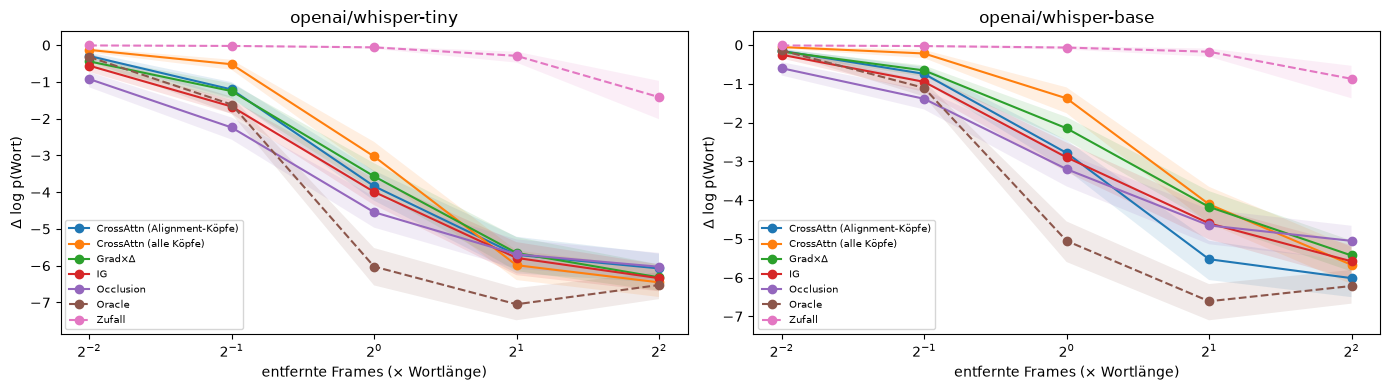

In [18]:
D = pd.concat([RES[m]["deletion"] for m in MODELS])
curves = D.groupby(["model", "method", "frac"]).delta.mean().unstack("frac")
display(curves.round(2))

AW = D.groupby(["model", "method", "utt", "wi"]).delta.mean().rename("auc").reset_index()   # AUC je Wort
rows = []
for (m, meth), d in AW.groupby(["model", "method"]):
    lo, hi = boot_ci(d, "auc")
    rows.append(dict(model=m.split("/")[-1], method=meth, AUC=d.auc.mean(), KI_unten=lo, KI_oben=hi))
auc = pd.DataFrame(rows).sort_values(["model", "AUC"]).set_index(["model", "method"]).round(2)
display(auc)

# gepaarte Vergleiche: negative Differenz = erste Methode fällt steiler (treuer)
PV = AW.pivot_table(index=["model", "utt", "wi"], columns="method", values="auc").reset_index()
pairs = [("CrossAttn (Alignment-Köpfe)", "IG"), ("CrossAttn (Alignment-Köpfe)", "Occlusion"),
         ("CrossAttn (alle Köpfe)", "IG"), ("Occlusion", "IG"), ("Grad×Δ", "IG")]
rows = []
for m, d in PV.groupby("model"):
    for a, b in pairs:
        if a not in d or b not in d: continue
        dd = d.assign(diff=d[a] - d[b]); lo, hi = boot_ci(dd, "diff"); du = dd.groupby("utt")["diff"].mean()
        rows.append(dict(model=m.split("/")[-1], Vergleich=f"{a} − {b}", Differenz=dd["diff"].mean(), KI_unten=lo, KI_oben=hi,
                         p_Wilcoxon=stats.wilcoxon(du).pvalue))
PAIR = pd.DataFrame(rows); PAIR["p_Holm"] = holm(PAIR.p_Wilcoxon)
display(PAIR.set_index(["model", "Vergleich"]).style.format({"Differenz": "{:+.2f}", "KI_unten": "{:+.2f}", "KI_oben": "{:+.2f}",
                                                              "p_Wilcoxon": "{:.2g}", "p_Holm": "{:.2g}"}))

fig, ax = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 4), squeeze=False)
for a, m in zip(ax[0], MODELS):
    for meth, d in D[D.model == m].groupby("method"):
        fr = sorted(d.frac.unique()); mu = [d[d.frac == f].delta.mean() for f in fr]
        ci = np.array([boot_ci(d[d.frac == f], "delta", n=500) for f in fr])
        ls = "--" if meth in ("Oracle", "Zufall") else "-"
        a.plot(fr, mu, marker="o", ls=ls, label=meth); a.fill_between(fr, ci[:, 0], ci[:, 1], alpha=0.12)
    a.set_xscale("log", base=2); a.set_xlabel("entfernte Frames (× Wortlänge)"); a.set_ylabel("Δ log p(Wort)"); a.set_title(m); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/tf5_deletion.png", dpi=130); plt.show()

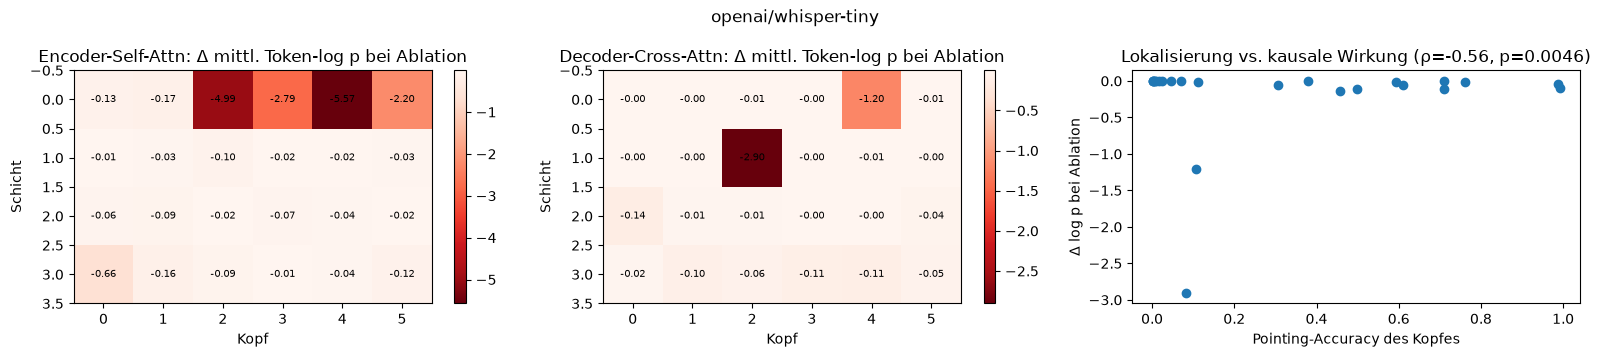

openai/whisper-tiny: Spearman(Pointing, Δ log p) = -0.56; Kendall τ = -0.34; Köpfe mit |Δ log p| < 0,01: 12/24
openai/whisper-tiny – Gruppenablation (Top-3 der Einzelablation: C1.2 (-2.90), C0.4 (-1.20), C2.0 (-0.14))


,label,Köpfe,Top-3 darin,Σ Einzel-Δ log p,d_logprob,wer,wer_capped,d_wer_capped,n_loop
48,alignment heads,C2.2 C3.0 C3.2 C3.3 C3.4 C3.5,–,-0.367,-1.556,2.054,0.812,0.738,8
49,Zufall 0,C0.1 C0.5 C1.1 C1.3 C3.0 C3.5,–,-0.080,-0.147,0.108,0.108,0.035,0
50,Zufall 1,C0.1 C0.5 C1.2 C3.1 C3.2 C3.4,C1.2,-3.186,-3.068,3.009,0.812,0.738,6
51,Zufall 2,C0.5 C1.2 C1.4 C2.1 C2.3 C3.5,C1.2,-2.982,-2.938,4.413,0.797,0.724,8
52,Zufall 3,C0.1 C0.2 C1.2 C1.3 C2.1 C2.2,C1.2,-2.940,-0.531,0.836,0.295,0.221,1
53,Zufall 4,C0.2 C0.5 C1.0 C1.4 C2.1 C3.2,–,-0.092,-0.109,0.116,0.116,0.042,0


  Spearman(Σ Einzel-Δ log p, Gruppen-Δ log p) über 6 Mengen = +0.89
  Beispiel (Zufall 2, WER 20.25):
    REF: you have been so ill my poor rachel
    HYP: You have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been so ill, you have been 


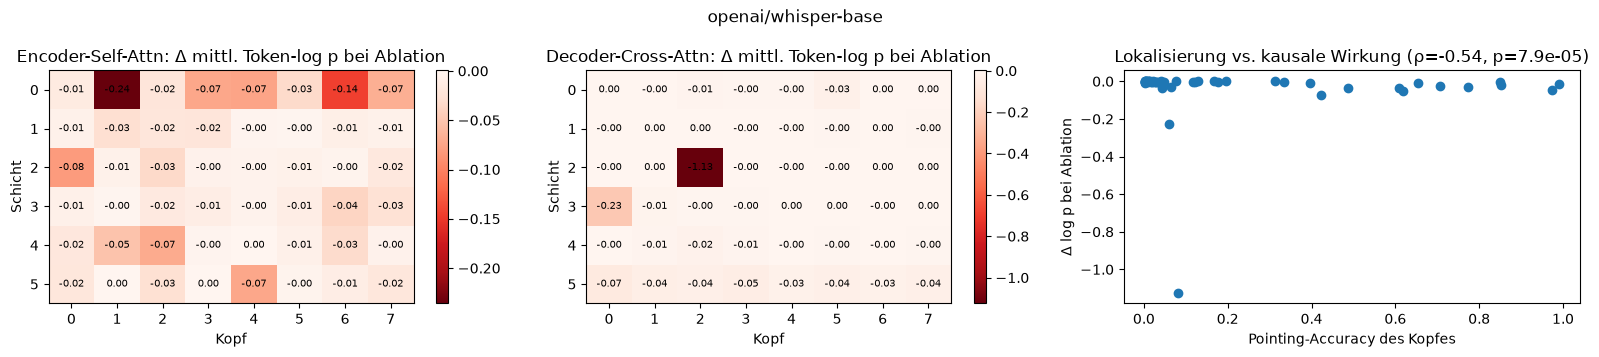

openai/whisper-base: Spearman(Pointing, Δ log p) = -0.54; Kendall τ = -0.37; Köpfe mit |Δ log p| < 0,01: 35/48
openai/whisper-base – Gruppenablation (Top-3 der Einzelablation: C2.2 (-1.13), C3.0 (-0.23), C5.0 (-0.07))


,label,Köpfe,Top-3 darin,Σ Einzel-Δ log p,d_logprob,wer,wer_capped,d_wer_capped,n_loop
96,alignment heads,C3.1 C4.2 C4.3 C4.7 C5.1 C5.2 C5.4 C5.6,–,-0.185,-1.562,0.913,0.590,0.521,2
97,Zufall 0,C0.4 C0.5 C1.2 C2.1 C2.5 C4.1 C5.5 C5.6,–,-0.107,-0.145,0.226,0.123,0.054,1
98,Zufall 1,C0.3 C1.2 C2.2 C2.6 C2.7 C5.3 C5.4 C5.7,C2.2,-1.242,-0.742,1.270,0.476,0.407,5
99,Zufall 2,C0.1 C0.5 C3.1 C3.4 C4.0 C4.5 C5.0 C5.4,C5.0,-0.152,-0.178,0.085,0.085,0.016,0
100,Zufall 3,C0.2 C0.4 C1.3 C2.6 C4.3 C4.5 C4.7 C5.0,C5.0,-0.101,-0.116,0.118,0.118,0.049,0
101,Zufall 4,C0.5 C1.2 C2.3 C2.4 C2.5 C3.5 C3.6 C4.2,–,-0.056,-0.103,0.079,0.079,0.010,0


  Spearman(Σ Einzel-Δ log p, Gruppen-Δ log p) über 6 Mengen = +0.94
  Beispiel (Zufall 1, WER 12.06):
    REF: grace be to you and peace from god the father and from our lord jesus christ
    HYP: Grace be to you and peace be to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you and to you 


In [19]:
for m in MODELS:
    r = RES[m]; A = r["ablation"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for a, kind, L, H, ttl in [(ax[0], "enc_self", r["L_enc"], r["H_enc"], "Encoder-Self-Attn"),
                               (ax[1], "dec_cross", r["L_dec"], r["H_dec"], "Decoder-Cross-Attn")]:
        d = A[(A.kind == kind) & A.label.str.match(r"^[EC]\d")]
        M = np.zeros((L, H))
        for _, row in d.iterrows(): (l, h), = row.heads; M[l, h] = row.d_logprob
        im = a.imshow(M, cmap="Reds_r", aspect="auto"); plt.colorbar(im, ax=a)
        for (l, h), v in np.ndenumerate(M): a.text(h, l, f"{v:.2f}", ha="center", va="center", fontsize=7)
        a.set_title(f"{ttl}: Δ mittl. Token-log p bei Ablation"); a.set_xlabel("Kopf"); a.set_ylabel("Schicht")
    d = A[(A.kind == "dec_cross") & A.label.str.match(r"^C\d")]
    loc = np.array([r["cross"]["hit"][row.heads[0]] for _, row in d.iterrows()])
    ax[2].scatter(loc, d.d_logprob); ax[2].set_xlabel("Pointing-Accuracy des Kopfes"); ax[2].set_ylabel("Δ log p bei Ablation")
    rho = stats.spearmanr(loc, d.d_logprob)
    ax[2].set_title(f"Lokalisierung vs. kausale Wirkung (ρ={rho.statistic:.2f}, p={rho.pvalue:.2g})")
    plt.suptitle(m); plt.tight_layout(); plt.savefig(f"{OUT}/tf5_ablation_{m.split('/')[-1]}.png", dpi=130); plt.show()
    print(f"{m}: Spearman(Pointing, Δ log p) = {rho.statistic:+.2f}; Kendall τ = {stats.kendalltau(loc, d.d_logprob).statistic:+.2f}; "
          f"Köpfe mit |Δ log p| < 0,01: {(d.d_logprob.abs() < 0.01).sum()}/{len(d)}")

    # Gruppenablation: Zusammensetzung der Zufallsmengen und Bezug zur Einzelablation
    single = {row.heads[0]: row.d_logprob for _, row in d.iterrows()}
    top3 = sorted(single, key=single.get)[:3]
    g = A[~A.label.str.match(r"^[EC]\d")].copy()
    g["Köpfe"] = g.heads.apply(lambda hs: " ".join(f"C{l}.{h}" for l, h in hs))
    g["Top-3 darin"] = g.heads.apply(lambda hs: " ".join(f"C{l}.{h}" for l, h in hs if (l, h) in top3) or "–")
    g["Σ Einzel-Δ log p"] = g.heads.apply(lambda hs: sum(single[(l, h)] for l, h in hs))
    print(f"{m} – Gruppenablation (Top-3 der Einzelablation: {', '.join(f'C{l}.{h} ({single[(l, h)]:.2f})' for l, h in top3)})")
    cols = ["label", "Köpfe", "Top-3 darin", "Σ Einzel-Δ log p", "d_logprob"]
    if "wer" in g:
        cols += ["wer", "wer_capped", "d_wer_capped", "n_loop"]
    display(g[cols].round(3))
    rs = stats.spearmanr(g["Σ Einzel-Δ log p"], g.d_logprob)
    print(f"  Spearman(Σ Einzel-Δ log p, Gruppen-Δ log p) über {len(g)} Mengen = {rs.statistic:+.2f}")
    if "wer" in g:
        worst = g.loc[g.wer.idxmax()]; j = int(np.argmax(worst.wers))
        ref = r["utt"].set_index("utt").loc[worst.utt_ids[j], "ref_text"]
        print(f"  Beispiel ({worst.label}, WER {worst.wers[j]:.2f}):\n    REF: {ref[:200]}\n    HYP: {worst.texts[j].strip()[:300]}")

### Interpretation TF5 – Faithfulness (H4)

**Deletion-Test**

* Alle Methoden schlagen Zufall deutlich (Zufall bei 4 × Wortlänge −1,41 / −0,87, die Methoden −5,0 bis −6,5). Keine erreicht das Oracle (MFA-Wortmitte): Bei 1 × Wortlänge liegt das Oracle bei −6,02 / −5,05, die beste Methode (Occlusion) bei −4,54 / −3,20.
* **Rangfolge nach AUC** (mittleres Δ log p, 95-%-KI): tiny: Occlusion −3,88 [−4,22; −3,57], IG −3,67, Grad×Δ −3,45, Alignment-Köpfe −3,42, alle Köpfe −3,22. base: Alignment-Köpfe −3,04 [−3,38; −2,76], Occlusion −2,98, IG −2,86, Grad×Δ −2,52, alle Köpfe −2,29.
* **H4a teilweise bestätigt.** Die gepaarten Tests wurden nach dem ersten Lauf ergänzt und sind explorativ. Gepaarte Vergleiche über dieselben Wörter (Holm-korrigiert innerhalb der Tabelle, in Klammern die globale Korrektur aus Abschnitt 13b):
  - Der **Mittelwert über alle Köpfe** ist in beiden Modellen signifikant weniger treu als IG (Differenz +0,45 [+0,30; +0,58] bzw. +0,57 [+0,40; +0,72]).
  - Die **Alignment-Köpfe** liegen bei tiny hinter IG (+0,25 [+0,12; +0,36], p = 0,024; global p = 0,081, also nicht mehr signifikant) und signifikant hinter Occlusion (+0,46, p < 0,001). Bei base sind sie dagegen **treuer als IG** (−0,19 [−0,35; −0,05], p = 0,011; global p = 0,026) und gleichauf mit Occlusion (p = 0,49).
  - „Attention ist schwächer faithful als Attribution“ gilt damit für ungefilterte Attention und für tiny, nicht aber für die Alignment-Köpfe von base.
* Occlusion ist bei kleinen Anteilen (0,25–1 ×) am treuesten. Das ist zu erwarten, weil sie genau die Größe misst, die der Test bewertet. Grad×Δ ist in beiden Modellen signifikant weniger treu als IG (+0,22 / +0,34); das passt zur Sättigung lokaler Gradienten.
* Der **Out-of-Distribution-Effekt** (Hooker et al., 2019) bleibt: Das Setzen auf Stille erzeugt Eingaben, die Whisper nie gesehen hat.
* **Das Oracle ist nicht monoton:** Bei 4 × Wortlänge fällt log p weniger stark als bei 2 × (tiny −6,53 gegen −7,05, base −6,22 gegen −6,61). Mehr entfernte Information macht das Wort also wieder *wahrscheinlicher*. Informationsverlust allein kann das nicht erklären. Plausibel ist, dass große zusammenhängende Stille-Blöcke die Eingabe so weit aus der Trainingsverteilung schieben, dass das Modell stärker auf den Decoder-Kontext (Sprachmodell) zurückfällt und das per Teacher Forcing vorgegebene Wort wieder wahrscheinlicher wird. Das ist ein direkter Hinweis auf den OOD-Effekt und ein Grund, die Werte bei großen Anteilen vorsichtig zu lesen.

**Einzelkopf-Ablation**

* **H4b bestätigt:** Die kausal wichtigsten Cross-Attention-Köpfe lokalisieren schlecht: bei tiny Schicht 1 / Kopf 2 (Δ log p = −2,90, Pointing 0,08) und Schicht 0 / Kopf 4 (−1,20 / 0,11), bei base Schicht 2 / Kopf 2 (−1,13 / 0,08) und Schicht 3 / Kopf 0 (−0,23 / 0,06). Köpfe mit Pointing > 0,5 ändern das Token-log p einzeln nur um 0 bis −0,11 (tiny) bzw. 0 bis −0,05 (base).
* Spearman ρ = −0,56 / −0,54 (Kendall τ = −0,34 / −0,37). Das negative Vorzeichen ist als Rangeffekt zu lesen: Viele nicht lokalisierende Köpfe haben eine Wirkung von praktisch 0 (|Δ log p| < 0,01 bei 12 von 24 bzw. 35 von 48 Köpfen), gut lokalisierende Köpfe kleine, aber von 0 verschiedene Effekte. Es bedeutet nicht, dass schlecht lokalisierende Köpfe im Mittel wichtiger wären. Nach globaler Korrektur ist die Korrelation nur bei base signifikant (p = 0,001; tiny p = 0,055). Für H4b entscheidend ist ohnehin der Befund, dass die kausal wichtigsten Köpfe schlecht lokalisieren.
* Im **Encoder** konzentriert sich die Wirkung auf Schicht 0. Bei tiny ist sie sehr groß (Kopf 4: −5,57, Kopf 2: −4,99, Kopf 3: −2,79, Kopf 5: −2,20); das sind die lokalen bzw. diagonalen Köpfe (Vorgänger, Nachfolger, teils lokal). Bei base ist der größte Einzeleffekt klein (Schicht 0 / Kopf 1: −0,24), das Modell ist redundanter.

**Gruppenablation: Alignment-Köpfe gegen Zufallsmengen**

* **Die Alignment-Köpfe wirken als Gruppe.** Ihre Einzeleffekte summieren sich nur auf −0,37 (tiny) bzw. −0,19 (base). Gemeinsam abgeschaltet sinkt log p dagegen in beiden Modellen um 1,56, die gekappte WER steigt um +0,74 bzw. +0,52, und in 8 bzw. 2 der 25 Äußerungen entstehen Wiederholungsschleifen. Einzeln sind die Köpfe also redundant, zusammen sind sie wichtig.
* **Vergleich mit Zufallsmengen gleicher Größe:** Bei base schadet keine der fünf Zufallsmengen so stark wie die Alignment-Köpfe (Δ log p höchstens −0,74, gekappte ΔWER höchstens +0,41, Median +0,05). Bei tiny schaden zwei Zufallsmengen genauso stark oder stärker (Δ log p −3,07 und −2,94, gekappte ΔWER +0,74 und +0,72); der Median der Zufallsmengen liegt aber nur bei +0,22.
* **Erklärung, jetzt geprüft:** Gerade die Zufallsmengen mit großer Wirkung enthalten den kausal stärksten Einzelkopf (tiny Schicht 1 / Kopf 2 in „Zufall 1“ und „Zufall 2“, base Schicht 2 / Kopf 2 in „Zufall 1“). Die Summe der Einzeleffekte sagt die Gruppenwirkung über die sechs Mengen gut voraus (Spearman 0,89 / 0,94). Eine Ausnahme ist tiny „Zufall 3“: Sie enthält ebenfalls Schicht 1 / Kopf 2, schadet als Gruppe aber deutlich weniger (−0,53). Kopfeffekte addieren sich also nicht immer.
* **WER über 100 %:** Ungekappte WER-Werte bis 4,4 entstehen durch **Wiederholungsschleifen**, die jetzt erkannt und gespeichert werden. Beispiel (tiny, „Zufall 2“): Referenz „you have been so ill my poor rachel“, Ausgabe „You have been so ill, you have been so ill, …“ bis zum Token-Limit. Für Vergleiche wird deshalb die je Äußerung auf 1 gekappte WER verwendet.
* **Grenzen der Ablation:** Abgeschaltete Köpfe werden auf 0 gesetzt (Null-Ablation). Auch das ist ein Eingriff außerhalb der Trainingsverteilung; eine Mittelwert-Ablation wäre schonender. Die Zufallsmengen werden aus allen Schichten gezogen, die Alignment-Köpfe liegen aber fast nur in den späten Schichten. Ein fairer Vergleich bräuchte Zufallsmengen aus denselben Schichten. Beides erfordert einen neuen Ablationslauf.
* **Stichprobe:** Deletion und Ablation beruhen auf 25 Äußerungen, die Gruppenablation auf fünf Zufallsmengen und einem Seed. Die Gruppenvergleiche sind deshalb beschreibend.

## 13 Modellvergleich tiny vs. base

In [20]:
rows = []
for m in MODELS:
    r = RES[m]; w = r["words"]; A = r["ablation"]
    ig = w[w.method == "IG"]
    aw = r["deletion"].groupby(["method", "utt", "wi"]).delta.mean().rename("auc").reset_index()
    da = lambda meth: aw[aw.method == meth].auc.mean()
    row = dict(model=m, WER=r["utt"].wer.mean(), korrekte_Woerter=int(r["utt"].n_matched.sum()),
               IG_completeness_median=ig.ig_err.median(), IG_mass_in=ig.mass_in.mean(), IG_lift=ig.lift.median(),
               IG_pointing=ig.hit.mean(), Occlusion_pointing=w[w.method == "Occlusion"].hit.mean(),
               pointing_chance=ig.hit_chance.mean(),
               best_cross_head=r["cross"]["hit"].max(), mean_cross_head=r["cross"]["hit"].mean(),
               enc_local_first=r["enc"]["local"][0].mean(), enc_local_last=r["enc"]["local"][-1].mean(),
               enc_pad_mass=r["enc"]["pad_mass"].mean(),
               del_auc_IG=da("IG"), del_auc_Occlusion=da("Occlusion"), del_auc_CrossAttn_align=da("CrossAttn (Alignment-Köpfe)"),
               del_auc_Oracle=da("Oracle"), del_auc_Zufall=da("Zufall"))
    if r["align"]:
        row["align_heads_pointing"] = np.mean([r["cross"]["hit"][l, h] for l, h in r["align"]])
        if "d_wer_capped" in A:
            g = A[A.label == "alignment heads"].iloc[0]; z = A[A.label.str.startswith("Zufall")]
            row.update(dWERcap_align_heads=g.d_wer_capped, dWERcap_random_median=z.d_wer_capped.median(),
                       dWERcap_random_min=z.d_wer_capped.min(), dWERcap_random_max=z.d_wer_capped.max())
    rows.append(row)
CMP = pd.DataFrame(rows).set_index("model").T.astype(float).round(3); display(CMP)
CMP.to_csv(f"{OUT}/model_comparison.csv")
with open(f"{OUT}/summary.json", "w") as f:
    json.dump(dict(summary=summary.reset_index().to_dict("records"), comparison=CMP.to_dict(), cfg=CFG), f, indent=1, default=str)

model,openai/whisper-tiny,openai/whisper-base
WER,0.075,0.052
korrekte_Woerter,1756.000,1779.000
IG_completeness_median,0.002,0.003
IG_mass_in,0.230,0.208
IG_lift,6.251,5.426
IG_pointing,0.790,0.765
Occlusion_pointing,0.916,0.864
pointing_chance,0.049,0.049
best_cross_head,0.991,0.991
mean_cross_head,0.312,0.220


## 13b Exporte und globale Mehrfachtest-Korrektur

**Exporte.** Damit die Auswertung ohne den 18,7-stündigen Lauf nachvollziehbar ist, werden alle Zwischenergebnisse als CSV/JSON nach `results/` geschrieben: die verwendeten Äußerungen (IDs, Referenz, Hypothese, WER), Deletion, Ablation samt generierter Texte, Kennzahlen je Cross-Attention- und Encoder-Kopf, Band-Occlusion und IG-Konvergenz.

**Globale Mehrfachtest-Korrektur.** In den Abschnitten 8–12 wird nur innerhalb jeder Tabelle nach Holm korrigiert. Hier werden alle inferenzstatistischen Tests des Notebooks zusammengefasst und gemeinsam korrigiert. Die Spalte `Art` trennt Tests, die schon im ursprünglichen Analyseplan standen (*geplant*), von Tests, die erst nach dem ersten Lauf ergänzt wurden. Letztere sind **explorativ** zu lesen.

In [21]:
for m in MODELS:
    r, s = RES[m], m.split("/")[-1]
    r["utt"].to_csv(f"{OUT}/{s}_utterances.csv", index=False)
    r["deletion"].to_csv(f"{OUT}/{s}_deletion.csv", index=False)
    r["bands"].to_csv(f"{OUT}/{s}_band_occlusion.csv", index=False)
    A = r["ablation"].copy()
    A["heads"] = A.heads.apply(lambda hs: " ".join(f"{l}.{h}" for l, h in hs))
    A.drop(columns=[c for c in ("texts", "wers", "utt_ids") if c in A]).to_csv(f"{OUT}/{s}_ablation.csv", index=False)
    if "texts" in A:
        with open(f"{OUT}/{s}_ablation_texts.json", "w", encoding="utf-8") as f:
            json.dump({row.label: [dict(utt=u, wer=float(w), text=t) for u, w, t in zip(row.utt_ids, row.wers, row.texts)]
                       for row in A.itertuples()}, f, ensure_ascii=False, indent=1)
    for kind, mats in (("cross_heads", r["cross"]), ("encoder_heads", r["enc"])):
        L, H = next(iter(mats.values())).shape
        pd.DataFrame(dict(layer=np.repeat(np.arange(L), H), head=np.tile(np.arange(H), L), **{k: v.ravel() for k, v in mats.items()})
                     ).to_csv(f"{OUT}/{s}_{kind}.csv", index=False)
pd.concat([RES[m]["ig_conv"] for m in MODELS]).to_csv(f"{OUT}/ig_convergence.csv", index=False)
print("Exportiert:", ", ".join(sorted(f for f in os.listdir(OUT) if f.endswith((".csv", ".json")))))

Exportiert: ig_convergence.csv, model_comparison.csv, summary.json, whisper-base_ablation.csv, whisper-base_ablation_texts.json, whisper-base_band_occlusion.csv, whisper-base_cross_heads.csv, whisper-base_deletion.csv, whisper-base_encoder_heads.csv, whisper-base_utterances.csv, whisper-base_word_metrics.csv, whisper-tiny_ablation.csv, whisper-tiny_ablation_texts.json, whisper-tiny_band_occlusion.csv, whisper-tiny_cross_heads.csv, whisper-tiny_deletion.csv, whisper-tiny_encoder_heads.csv, whisper-tiny_utterances.csv, whisper-tiny_word_metrics.csv


In [22]:
TESTS = []
for _, r in T1.iterrows():
    TESTS.append(dict(Hypothese="H1", Test=f"mass_in über Zufall · {r.model} · {r.method}", Art="geplant", p=r.p_mass_in_gt_chance))
    TESTS.append(dict(Hypothese="H1", Test=f"Kontext nach vs. vor · {r.model} · {r.method}", Art="geplant", p=r.p_after_vs_before))
TESTS += H3_TESTS
for _, r in PAIR.iterrows():
    TESTS.append(dict(Hypothese="H4a" if "CrossAttn" in r.Vergleich else "Methodenvergleich",
                      Test=f"Deletion-AUC {r.Vergleich} · {r.model}", Art="nach erstem Lauf ergänzt", p=r.p_Wilcoxon))
for m in MODELS:
    A = RES[m]["ablation"]; d = A[(A.kind == "dec_cross") & A.label.str.match(r"^C\d")]
    rho = stats.spearmanr([RES[m]["cross"]["hit"][h[0]] for h in d.heads], d.d_logprob)
    TESTS.append(dict(Hypothese="H4b", Test=f"Spearman(Pointing, Δ log p) · {m.split('/')[-1]}", Art="geplant", p=rho.pvalue))
G = pd.DataFrame(TESTS)
G["p_Holm_global"] = holm(G.p)
G["sig. lokal"] = G.p < 0.05
G["sig. global"] = G.p_Holm_global < 0.05
display(G.style.format({"p": "{:.2g}", "p_Holm_global": "{:.2g}"}))
lost = G[G["sig. lokal"] & ~G["sig. global"]]
print(f"{len(G)} Tests ({(G.Art == 'geplant').sum()} geplant, {(G.Art != 'geplant').sum()} nach dem ersten Lauf ergänzt). "
      f"Signifikant ohne Korrektur: {G['sig. lokal'].sum()}, nach globaler Holm-Korrektur: {G['sig. global'].sum()}.")
print("Verlieren durch die globale Korrektur die Signifikanz:" if len(lost) else "Kein Test verliert durch die globale Korrektur die Signifikanz.")
for _, r in lost.iterrows():
    print(f"  {r.Hypothese}: {r.Test} (p = {r.p:.3g} → {r.p_Holm_global:.3g})")

,Hypothese,Test,Art,p,p_Holm_global,sig. lokal,sig. global
0,H1,mass_in über Zufall · whisper-base · CrossAttn (Alignment-Köpfe),geplant,1.9e-18,7.8e-17,True,True
1,H1,Kontext nach vs. vor · whisper-base · CrossAttn (Alignment-Köpfe),geplant,6.5e-13,1.6e-11,True,True
2,H1,mass_in über Zufall · whisper-base · CrossAttn (alle Köpfe),geplant,1.9e-18,7.8e-17,True,True
3,H1,Kontext nach vs. vor · whisper-base · CrossAttn (alle Köpfe),geplant,4.3e-18,1.2e-16,True,True
4,H1,mass_in über Zufall · whisper-base · Grad×Δ,geplant,1.9e-18,7.8e-17,True,True
5,H1,Kontext nach vs. vor · whisper-base · Grad×Δ,geplant,0.027,0.24,True,False
6,H1,mass_in über Zufall · whisper-base · IG,geplant,1.9e-18,7.8e-17,True,True
7,H1,Kontext nach vs. vor · whisper-base · IG,geplant,7.4e-05,0.0013,True,True
8,H1,mass_in über Zufall · whisper-base · Occlusion,geplant,1.9e-18,7.8e-17,True,True
9,H1,Kontext nach vs. vor · whisper-base · Occlusion,geplant,0.0073,0.081,True,False


40 Tests (26 geplant, 14 nach dem ersten Lauf ergänzt). Signifikant ohne Korrektur: 33, nach globaler Holm-Korrektur: 28.
Verlieren durch die globale Korrektur die Signifikanz:
  H1: Kontext nach vs. vor · whisper-base · Grad×Δ (p = 0.027 → 0.243)
  H1: Kontext nach vs. vor · whisper-base · Occlusion (p = 0.00732 → 0.0805)
  H3: Köpfe: Spearman(Schicht, local) negativ · whisper-base (p = 0.0383 → 0.307)
  H4a: Deletion-AUC CrossAttn (Alignment-Köpfe) − IG · whisper-tiny (p = 0.00807 → 0.0807)
  H4b: Spearman(Pointing, Δ log p) · whisper-tiny (p = 0.00458 → 0.055)


## 14 Fazit – Beantwortung der Hypothesen

### Skalierung tiny vs. base (Abschnitt 13)

* `whisper-base` ist genauer (WER 0,052 gegen 0,075). Die IG-Attribution ist bei beiden ähnlich (Pointing 0,79 / 0,77), bei base aber etwas diffuser (`lift` 5,4 gegen 6,3).
* Die **Alignment-Köpfe lokalisieren in base deutlich besser** (Pointing 0,73 gegen 0,58, ohne den Nachlauf-Versatz von tiny). Gleichzeitig sind relativ weniger Köpfe lokalisierend (Mittel 0,22 gegen 0,31), und die Padding-Masse im Encoder ist höher (0,12 gegen 0,075).
* `whisper-base` ist **robuster** gegen Frame-Deletion (IG-AUC −2,86 gegen −3,67) und gegen die Ablation einzelner Encoder-Köpfe (max. −0,24 gegen −5,57). Das größere Modell ist redundanter.
* Bei base ist die Gruppe der Alignment-Köpfe kausal wichtiger als jede Zufallsmenge. Bei tiny dominiert dagegen ein einzelner, nicht lokalisierender Kopf (Decoder-Schicht 1 / Kopf 2).
* Beide Modelle sind klein, Aussagen über größere Whisper-Modelle lassen sich daraus nicht ableiten.

### Hypothesen

Mit *explorativ* gekennzeichnete Bewertungen beruhen auf Tests, die erst nach dem ersten Lauf ergänzt wurden (Abschnitt 13b). „Global“ bezieht sich auf die gemeinsame Holm-Korrektur aller 40 Tests.

| | Hypothese | Ergebnis | Begründung |
|---|---|---|---|
| **H1** | Attribution liegt über Zufall im Wortsegment, mit Kontext von wenigen 100 ms. | **Bestätigt** | `mass_in` > `chance` in allen 100 Äußerungen beider Modelle (Holm-korrigiert p < 1e-16), `lift` 4,4–18,6, symmetrischer Kontext (je ca. 0,09–0,11). IG konvergiert (Fehler 0,2 % / 0,3 %), Occlusion am schärfsten. |
| **H2** | Nur wenige Cross-Attention-Köpfe lokalisieren, und es sind die Alignment-Köpfe. | **Teilweise bestätigt** | 7/24 bzw. 9/48 Köpfe mit Pointing > 0,5, vor allem in späten Schichten. Alignment-Köpfe im Mittel besser (0,58 / 0,73 gegen 0,31 / 0,22), aber nicht die besten (Top-k-Überlappung 3/6 und 7/8); in base ist einer ein Sink. |
| **H3** | Frühe Encoder-Schichten sind lokal, späte global. | **Teilweise bestätigt (explorativ)** | Der geplante Test über die Köpfe ist global in keinem Modell signifikant. Explorativ sinkt die Lokalität mit der Schicht in allen 100 Äußerungen beider Modelle (p < 1e-16). Die Aufmerksamkeitsdistanz wächst nur bei base. |
| **H4a** | Deletion-Kurven von IG und Occlusion fallen steiler als die der Cross-Attention. | **Teilweise bestätigt (explorativ getestet)** | Über alle Köpfe gemittelte Attention ist signifikant weniger treu als IG. Die Alignment-Köpfe sind bei base treuer als IG (−0,19) und gleichauf mit Occlusion. Bei tiny liegen sie hinter IG (+0,25), global aber nicht signifikant; hinter Occlusion liegen sie signifikant. |
| **H4b** | Lokalisierungsgüte eines Kopfes sagt seine Ablationswirkung nur schwach voraus. | **Bestätigt** | Die stärksten Ablationseffekte stammen von schlecht lokalisierenden Köpfen (Pointing ≈ 0,1). Gut lokalisierende Köpfe haben einzeln kaum Wirkung. Spearman ρ = −0,56 / −0,54 (global nur bei base signifikant). |

### Fazit

1. Whisper hört im Wesentlichen **im Wortsegment** hin, mit einem Kontext von wenigen 100 ms in beide Richtungen. Das zeigen alle Methoden, am schärfsten Occlusion.
2. Spektral zählt vor allem der Bereich **410–745 Hz**, auch pro Einheit Energie. Die Ähnlichkeit von IG-Karten und Energie ist dagegen größtenteils ein Artefakt der IG-Definition.
3. **Attention taugt zur Lokalisierung nur in wenigen, ausgewählten Köpfen** der letzten Decoder-Schichten. Die `alignment_heads` sind dafür eine gute, aber keine optimale Wahl.
4. **Lokalisierung ist nicht Wichtigkeit, aber Redundanz verdeckt Wichtigkeit.** Einzeln sind gut lokalisierende Köpfe kausal fast bedeutungslos, die wichtigsten Einzelköpfe lokalisieren schlecht. Als Gruppe sind die Alignment-Köpfe dagegen wichtig, bei base wichtiger als jede Zufallsmenge gleicher Größe.
5. Ob Attention weniger faithful ist als Attribution, **hängt von der Kopfauswahl und vom Modell ab**. Ungefilterte Attention ist schwächer, die Alignment-Köpfe von base sind sogar treuer als IG. Der Deletion-Test deckt aber nur eine Seite ab; die Einzelkopf-Ablation (H4b) zeigt die Grenze der Attention als Erklärung (Jain & Wallace, 2019).
6. Im Encoder nimmt die **Lokalität über die Schichten bei jeder Eingabe ab** (explorativ); über die Köpfe ist der Trend nicht signifikant. Ein klarer Übergang zu weitreichender Attention zeigt sich nur bei base.

### Grenzen und Fehlerquellen

**Studiendesign und Statistik**
* **Explorative Analysen:** Der Test auf Äußerungsebene für H3, die gepaarten Deletion-Vergleiche für H4a und die Regression zur Wortdauer wurden nach dem ersten Lauf ergänzt. Sie stützen Bewertungen in der Hypothesentabelle und sind entsprechend gekennzeichnet; eine Bestätigung an neuen Daten steht aus.
* **Mehrfachtests:** Global korrigiert verlieren 5 von 33 nominal signifikanten Tests die Signifikanz (Abschnitt 13b), darunter H3 auf Kopfebene, H4a bei tiny und H4b bei tiny.
* **Stichprobe:** 100 Äußerungen für die Lokalisierung, nur 25 für Deletion und Ablation, ein Seed und fünf Zufallsmengen für die Gruppenablation. Die Bootstrap-Intervalle erfassen nur die Unsicherheit über Äußerungen; mit 25 Clustern sind Perzentil-Intervalle eher zu schmal.
* **Test auf Äußerungsebene für H3:** Er verallgemeinert über Eingaben, nicht über Köpfe oder Modelle.

**Methoden**
* **Out-of-Distribution-Effekt** (Hooker et al., 2019) beim Entfernen von Frames und beim Nullsetzen von Köpfen. Das nicht-monotone Oracle zeigt ihn direkt. Die Stille-Baseline mildert ihn nur, und eine zweite Baseline wurde nicht geprüft.
* **Vorzeichen der Attribution:** Für die Zeitprofile werden Beträge |IG| und |Grad×Δ| verwendet, bei Occlusion nur der positive Teil. Evidenz *gegen* ein Wort zählt bei IG also als Relevanz, bei Occlusion nicht. Die Methoden messen damit nicht exakt dasselbe.
* **Unterschiedliche Zeitauflösung:** Attention arbeitet mit 20 ms, Attribution mit 10 ms, die Toleranz beträgt 20 ms. Pointing und `mass_in` sind zwischen Attention und Attribution deshalb nicht vollständig vergleichbar.
* **Kein Sanity-Check der Erklärungen:** Ob sich die IG-Karten bei randomisierten Modellgewichten ändern (Adebayo et al., 2018), wurde nicht geprüft.
* **Ablation:** Null-Ablation statt Mittelwert-Ablation; Zufallsmengen aus allen Schichten statt aus denselben Schichten wie die Alignment-Köpfe.
* **Zeitstempel:** Whispers eigenes Verfahren (Medianfilter und DTW über die Alignment-Köpfe) wurde nicht nachgebildet. Aussagen über Zeitstempel beziehen sich nur auf die rohe Attention.
* **WER unter Ablation:** Schleifen werden per Heuristik erkannt (Länge > 1,5 × Referenz oder Kompressionsrate > 2,4). Die gekappte WER ist robust, verliert aber die Information, *wie* stark ein Modell halluziniert.
* **Baseline-Abhängigkeit** von IG und Occlusion, **MFA-Ungenauigkeit** (ca. 10–20 ms bei 20 ms Toleranz), **Selektionsbias** (nur korrekt erkannte Wörter), **Teacher Forcing** auf die eigene Hypothese, Wörter aus mehreren Tokens.
* **Grobe Merkmale:** Die Funktionswortliste ist selbst zusammengestellt, die acht Mel-Bandgruppen sind zu grob, um Formanten von Harmonischen zu trennen.

**Geltungsbereich**
* Nur vorgelesenes, sauberes Englisch (LibriSpeech `test-clean`) und zwei kleine Modelle.

### Offene Punkte (erfordern einen neuen Lauf)

1. Mittelwert-Ablation statt Null-Ablation und Zufallsmengen aus denselben Schichten wie die Alignment-Köpfe (nur Ablation, geschätzt 1–2 Stunden).
2. Deletion mit einer zweiten Baseline (z. B. Rauschen), um die Rangfolge der Methoden abzusichern.
3. Mehr Äußerungen und mehrere Seeds für Deletion und Ablation.
4. Zeitprofile aller Methoden auf gemeinsamer 20-ms-Auflösung (die Profile selbst sind nicht gespeichert).
5. Modell-Randomisierungstest für IG und Occlusion.
6. Auswertung falsch erkannter Wörter und größerer Whisper-Modelle bzw. anderer Daten.
7. Bestätigung der explorativen Befunde (H3 auf Äußerungsebene, H4a) an neuen Äußerungen.
